# 06 — El cálculo con los perfiles **reales** de HMI

Este notebook repite el experimento del artefacto `OBS_VR` sobre umbras, pero
cambiando los tres eslabones sintéticos de `hmi_artifact_sim` por los **reales
del pipeline del JSOC**, y mirando en particular qué pasa con la corrección del
efecto Zeeman.

|   | versión sintética (notebooks 01–05) | **este notebook** |
|---|---|---|
| muestreo de los 6 filtros | delta: `I_j = L(λ_j)` | integral real `I_j = Σ T_j(λ)·L(λ)` con los 6 perfiles de transmisión reconstruidos píxel a píxel |
| línea Fe I de Sol quieto | gaussiana, `Id = 0.55`, FWHM ≈ 100 mÅ | la del pipeline: pseudo-Voigt + 2 gaussianas de ala, con escalado centro–limbo |
| escala fase → velocidad | `T = 6·68.8 mÅ` ⇒ ±10 023 m/s | `pv1 = dvtune·(N−1)` ⇒ ±8 202 m/s |
| tabla de inversión | construida por nosotros desde la gaussiana | la **LUT real** `hmi.lookup_corrected_expanded`, descargada del JSOC, **y** nuestra reconstrucción como control |

Todo lo que se descarga es público y no necesita cuenta en el JSOC.

**Cómo leerlo.** Cada sección empieza con una explicación, sigue con el
*pseudocódigo* de las funciones que se importan (para no tener que abrir los
módulos) y termina con el cálculo y su figura.

Entorno: `conda activate sun-spots`.

In [1]:
"""Estilo de presentacion, copiado de 05_plots.ipynb para que las
figuras de este notebook encajen con las del resto del paper."""

import pathlib

import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.font_manager import FontProperties, findfont

# ── colour ────────────────────────────────────────────────────────────────────
C_SERIES_3 = '#7C2D12'   # Umbra     — darkest, the subject
C_SERIES_4 = '#B45309'   # Penumbra
C_SERIES_1 = '#E8890C'   # Both
C_SERIES_2 = '#FCD34D'   # Quiet Sun — lightest, the baseline
C_ACCENT   = '#D97706'   # single-series highlight
C_INK      = '#241A12'   # text and axes
C_GRID     = '#E7DCCC'   # grid
C_FIG_BG   = '#FDF8F1'   # figure background

PALETTE = [C_SERIES_1, C_SERIES_2, C_SERIES_3, C_SERIES_4]

# Region → colour, so "the umbra is always the darkest" holds in every figure.
REGION_COLOR = {
    'Umbra':     C_SERIES_1,
    'Penumbra':  C_SERIES_2,
    'Both':      C_SERIES_3,
    'Quiet Sun': C_SERIES_4,
}

# (label, metrics-key suffix), in drawing order.
REGIONS = [('Umbra', 'umb'), ('Penumbra', 'pen'),  ('Quiet Sun', 'quiet')]

# The same ramp as a sequential colormap — for quantities that are a magnitude
CMAP_AMBER = LinearSegmentedColormap.from_list(
    'amber', ['#451A03', C_SERIES_1, C_SERIES_2, C_SERIES_3, C_SERIES_4])

# ── typography ────────────────────────────────────────────────────────────────
FONT_SANS = ['Jost', 'IBM Plex Sans', 'DejaVu Sans']
FONT_MONO = ['JetBrains Mono', 'JetBrainsMono Nerd Font', 'DejaVu Sans Mono']

# ── sizes ─────────────────────────────────────────────────────────────────────
FS_TITLE  = 26
FS_LABEL  = 20
FS_TICK   = 17
FS_LEGEND = 18
FS_ANNOT  = 14

LW_SERIES = 2.4
LW_GRID   = 1.0
LW_SPINE  = 1.6

FIGSIZE_WIDE  = (16, 8)
FIGSIZE_STACK = (16, 10)
DPI_SHOW = 110
DPI_SAVE = 200

# ── output ───────────────────────────────────────────────────────────────────
SAVE = True
PLOTS_DIR = '../figures'

plt.rcParams.update({
    'font.family':      'sans-serif',
    'font.sans-serif':  FONT_SANS,
    'font.monospace':   FONT_MONO,
    'font.size':        FS_LABEL,

    'figure.figsize':     FIGSIZE_WIDE,
    'figure.dpi':         DPI_SHOW,
    'figure.facecolor':   C_FIG_BG,
    'figure.titlesize':   FS_TITLE,
    'figure.titleweight': 'semibold',

    'savefig.facecolor': C_FIG_BG,
    'savefig.dpi':       DPI_SAVE,
    'savefig.bbox':      'tight',

    'axes.facecolor':     C_FIG_BG,
    'axes.edgecolor':     C_INK,
    'axes.linewidth':     LW_SPINE,
    'axes.labelcolor':    C_INK,
    'axes.labelsize':     FS_LABEL,
    'axes.labelweight':   'medium',
    'axes.titlesize':     FS_TITLE,
    'axes.titleweight':   'semibold',
    'axes.titlecolor':    C_INK,
    'axes.titlepad':      14,
    'axes.spines.top':    False,
    'axes.spines.right':  False,
    'axes.prop_cycle':    cycler(color=PALETTE),
    'axes.grid':          True,
    'axes.axisbelow':     True,

    'grid.color':     C_GRID,
    'grid.linewidth': LW_GRID,
    'grid.alpha':     1.0,

    'lines.linewidth':       LW_SERIES,
    'lines.solid_capstyle':  'round',

    'text.color':        C_INK,
    'xtick.color':       C_INK,
    'ytick.color':       C_INK,
    'xtick.labelsize':   FS_TICK,
    'ytick.labelsize':   FS_TICK,
    'xtick.major.width': LW_SPINE,
    'ytick.major.width': LW_SPINE,
    'xtick.major.size':  6,
    'ytick.major.size':  6,

    'legend.fontsize':   FS_LEGEND,
    'legend.frameon':    True,
    'legend.facecolor':  C_FIG_BG,
    'legend.edgecolor':  C_GRID,
    'legend.framealpha': 1.0,
    'legend.borderpad':  0.6,
})

def mono_ticks(*axes):
    for ax in axes:
        for label in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
            label.set_fontfamily('monospace')
            label.set_fontsize(FS_TICK)

def save_fig(fig, name):
    if not SAVE or PLOTS_DIR is None:
        return
    out_dir = pathlib.Path(PLOTS_DIR)
    out_dir.mkdir(parents=True, exist_ok=True)
    out = out_dir / f'{name}.png'
    fig.savefig(out, dpi=DPI_SAVE, bbox_inches='tight', facecolor=C_FIG_BG)
    print(f'saved → {out}')

for role, stack in (('sans', FONT_SANS), ('mono', FONT_MONO)):
    resolved = pathlib.Path(findfont(FontProperties(family=stack))).name
    print(f'{role:5s} {stack[0]:20s} → {resolved}')

sans  Jost                 → IBMPlexSans-Regular.ttf
mono  JetBrains Mono       → JetBrainsMonoNerdFont-Regular.ttf


## §0 — Entorno y rutas

El paquete `hmi_artifact_sim` vive un directorio arriba. Los insumos reales se
cachean en `hmi_artifact_sim/data/`: la primera ejecución baja ~325 MB (tres
tablas de 107 MB más un megabyte de calibración), las siguientes no bajan nada.

In [2]:
import pathlib, sys, time
import numpy as np
import matplotlib.pyplot as plt

project_root = pathlib.Path.cwd()
while project_root != project_root.parent and not (project_root / 'hmi_artifact_sim').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root.resolve()))

from hmi_artifact_sim import config as cfg
from hmi_artifact_sim import jsoc_data as jd
from hmi_artifact_sim import real_filters as rfl
from hmi_artifact_sim import real_line as rl
from hmi_artifact_sim import real_pipeline as rp
from hmi_artifact_sim import real_artifact as ra
from hmi_artifact_sim import zeeman as zz
from hmi_artifact_sim.profiles import zeeman_shift
from hmi_artifact_sim.real_line import umbral_line

print('raiz del proyecto :', project_root)
print('cache de datos    :', jd.CACHE)
print('epocas disponibles:', {k: v for k, v in jd.EPOCHS.items()})

raiz del proyecto : /mnt/shared/Projects/sun_rotacion_sim
cache de datos    : /mnt/shared/Projects/sun_rotacion_sim/hmi_artifact_sim/data
epocas disponibles: {23845068: '2011-06-22', 65714753: '2013-12-18', 104314890: '2016-04-05'}


## §1 — Lo que cambia, en números

Antes de calcular nada conviene ver las constantes reales, porque algunas
difieren de las que supone `config.py` y entran directo en el resultado.

Tres hallazgos de leer el fuente oficial (`lev1.5_hmi/apps/HMI_lookup.c`) que
vale la pena tener presentes:

1. **`pv1 = dvtune·(N−1)`**, no `dvtune·N`. El propio fuente lo comenta:
   `WARNING THIS IS WRONG, SHOULD BE dvtune*N`. Con `dtune = FSR_NB/2.5`, eso
   da ±8.2 km/s de rango no ambiguo en vez de ±9.8 km/s, un factor 5/6 en la
   conversión fase → velocidad.
2. **El signo de la fase es `atan2(−f1s, −f1c)`**, que es exactamente lo que ya
   hacía `pipeline.velocity_from_coefficients` (la nota de su docstring queda
   confirmada contra el código oficial).
3. **La lectura de `ReferenceFeLine.bin` está comentada.** El repositorio trae
   el archivo con la línea de R. Ulrich, pero el pipeline **no lo usa**:
   construye la línea analíticamente. Usarlo por error introduce un sesgo de
   ~2.4 km/s, porque su mínimo cae en −62 mÅ y no en el centro (§3).

In [3]:
chk = jd.check_lookup_c_constants()
print('Constantes verificadas contra el fuente oficial HMI_lookup.c:')
for k, v in chk.items():
    print(f'  [{"OK" if v else "NO"}] {k}')
assert all(chk.values()), 'el fuente oficial cambio: revisar jsoc_data.py'

p = jd.parse_hmiparam()
dtune, dvtune, pv1, pv2 = rp.velocity_scale()
Lq = rl.quiet_line(1.0, 13)

filas = [
    ('separacion entre filtros', f'{1e3*cfg.DLAMBDA:.2f} mA',  f'{1e3*dtune:.2f} mA'),
    ('rango no ambiguo 1er Fourier', f'+-{cfg.V_UNAMBIGUOUS:.0f} m/s', f'+-{pv1/2:.0f} m/s'),
    ('rango no ambiguo 2do Fourier', '-',                      f'+-{pv2/2:.0f} m/s'),
    ('profundidad de linea (mu=1)',  f'{cfg.ID_QUIET:.3f}',    f'{Lq.Id:.3f}'),
    ('FWHM de linea (mu=1)',         f'{2*np.sqrt(np.log(2))*cfg.SIGMA_QUIET*1e3:.1f} mA',
                                     f'{Lq.measured_fwhm():.1f} mA'),
    ('puntos de la rejilla lambda',  '-',                      f'{32001}'),
    ('paso de la rejilla lambda',    '-',                      f'{1e3*p["dvtest"]*p["dlamdv"]:.4f} mA'),
    ('velocidades de prueba (LUT)',  f'{cfg.LUT_N}',           f'{p["ntest"]} cada {p["dvtest"]:.0f} m/s'),
]
w = max(len(f[0]) for f in filas)
print(f'\n{"":{w}}   {"sintetico":>14}   {"REAL":>16}')
print('-' * (w + 36))
for a, b, c in filas:
    print(f'{a:{w}}   {b:>14}   {c:>16}')
print(f'\nFSR [NB, WB, E1, E2, E3, E4, E5] = {p["FSR"]} A')

Constantes verificadas contra el fuente oficial HMI_lookup.c:
  [OK] minimumCoeffs
  [OK] FWHMCoeffs
  [OK] phaseE4+=0.4
  [OK] phaseE5-=1.1
  [OK] phaseNB obs-cal
  [OK] phaseWB obs-cal
  [OK] phaseE1 obs-cal
  [OK] pv1=dvtune*(N-1)
  [OK] atan2(-f1s,-f1c)
  [OK] mu=cos(asin(r/Rsun))

                                    sintetico               REAL
----------------------------------------------------------------
separacion entre filtros             68.80 mA           67.56 mA
rango no ambiguo 1er Fourier      +-10023 m/s         +-8202 m/s
rango no ambiguo 2do Fourier                -         +-4101 m/s
profundidad de linea (mu=1)             0.550              0.661
FWHM de linea (mu=1)                  99.9 mA            91.6 mA
puntos de la rejilla lambda                 -              32001
paso de la rejilla lambda                   -          0.4942 mA
velocidades de prueba (LUT)               821    821 cada 24 m/s

FSR [NB, WB, E1, E2, E3, E4, E5] = [ 0.1689   0.33685  0.695  

## §2 — De dónde sale cada perfil real

Dos fuentes, ninguna con registro:

**Repositorio oficial del JSOC** (`github.com/JSOC-SDP/proj`, rama `master`,
subárbol `lev1.5_hmi/`):

| archivo | qué aporta |
|---|---|
| `libs/lev15/HMIparam.h` | los 7 FSR, el blocker S/N 11 (201 puntos) y la front window S/N 3 (401 puntos) medidos, `ntest=821`, `dvtest=24 m/s`, `dlamdv`, `lam0` |
| `apps/non_tunable_phases_710660_June09_cal_128_2.bin` | fases de E2–E5 por píxel, en grados |
| `apps/non_tunable_contrasts_710660_June09_cal_128_2.bin` | contrastes de E2–E5 |
| `apps/tunable_contrasts_710660_June09_cal_128.bin` | contrastes de NB, WB, E1 |
| `apps/HMI_lookup.c` | el código que construye la LUT (lo usamos para verificar constantes) |

**Series DRMS públicas del JSOC**, vía el CGI `jsoc_info` y descarga directa del
segmento desde `/SUM*/`:

| serie | qué aporta |
|---|---|
| `hmi.phasemaps_extended[FSN]` | las fases de NB, WB y E1 del día (`phases`, 5×128×128), más `HCMNB/WB/E1`, `FSRNB…FSRE5`, `CBLOCKER`, `R_SUN`, `LW_MEAN` |
| `hmi.lookup_corrected_expanded[FSN]` | la **LUT real**, `lookup` de 1642×128×128 = 2×821 velocidades |

> **Nota.** `hmi.phasemaps_corrected`, la serie que suele citarse, **no** es
> accesible desde fuera de Stanford (`"not a valid series accessible from
> hmidb2"`). `hmi.phasemaps_extended` sí lo es y trae las mismas fases.

### Pseudocódigo de `jsoc_data`

```
parse_hmiparam():
    baja libs/lev15/HMIparam.h
    quita los comentarios de C   # hay 4 definiciones de FSR comentadas
    extrae por regex los arrays y escalares -> dict

load_calibration_bins(nx=128):
    for cada .bin:  np.fromfile(float32).reshape(n, nx, nx)
    # orden IDL phase[nx,nx,n] -> el elemento es el eje LENTO

jsoc_records(serie, fsn):
    GET jsoc.stanford.edu/cgi-bin/ajax/jsoc_info
        ?op=rs_list&ds=serie[fsn]&key=**ALL**&seg=**ALL**
    -> un dict por registro, con {'segments': {nombre: /SUM.../x.fits}}

fetch_segment(ruta_sums):
    GET jsoc1.stanford.edu<ruta_sums>  -> FITS local, cacheado

load_phasemap(fsn, hcamid=2):   -> phases[5,128,128] en grados + keywords
load_real_lut(fsn, hcamid=2):   -> lut[1642,128,128] + keywords
```

### Las tres épocas

Se comparan tres re-sintonías del instrumento, siempre con **`HCAMID = 2`**
(cámara lateral, la de los productos de 720 s).

**Detalle que importa:** las posiciones de sintonía para reproducir la LUT son
los `HWL4POS/HWL2POS/HWL1POS` (= NB/WB/E1) del registro de
`lookup_corrected_expanded`, **no** los `HCMNB/HCMWB/HCME1` del phasemap:
difieren en un paso de HCM (6°) en varias épocas. Usar los del phasemap es el
error silencioso más probable.

In [4]:
t0 = time.time()
EPOCAS = {}
for fsn, fecha in jd.EPOCHS.items():
    ph, pm = jd.load_phasemap(fsn)
    lr = jd._pick(jd.jsoc_records('hmi.lookup_corrected_expanded', fsn,
                  keys='HCAMID,NWL,HWL1POS,HWL2POS,HWL3POS,HWL4POS,COMMENT'),
                  HCAMID=2, NWL=6)
    EPOCAS[fsn] = dict(fecha=fecha, phases=ph, pm=pm, lut_rec=lr,
                       cal=rl.calibration_of(lr['COMMENT']),
                       hcm=jd.hcm_from_lut_record(lr))
    print(f'FSN {fsn}  {fecha}  T_REC={pm["T_REC"]}')
    print(f'    HCM del phasemap NB/WB/E1 = {pm["HCMNB"]}/{pm["HCMWB"]}/{pm["HCME1"]}')
    print(f'    HCM de la LUT     NB/WB/E1 = {EPOCAS[fsn]["hcm"]}      <- los que se usan')
    print(f'    calibracion de la linea    = {EPOCAS[fsn]["cal"]}   ({lr["COMMENT"]})')
    print(f'    LW_MEAN={pm["LW_MEAN"]} A   LD_MEAN={pm["LD_MEAN"]}   R_SUN={pm["R_SUN"]} px')

print(f'\nInsumos en cache ({time.time()-t0:.0f} s):')
tot = 0
for nombre, n in jd.cache_report():
    tot += n
    print(f'  {n/1e6:9.2f} MB  {nombre}')
print(f'  {tot/1e6:9.2f} MB  TOTAL')

FSN 23845068  2011-06-22  T_REC=2011.06.22_18:36:56_TAI
    HCM del phasemap NB/WB/E1 = 82/55/37
    HCM de la LUT     NB/WB/E1 = (82, 54, 37)      <- los que se usan
    calibracion de la linea    = 11   (Code used: lookup.c; CALIBRATION USED IS: 11)
    LW_MEAN=0.076919 A   LD_MEAN=630.785400   R_SUN=2015.500000 px
FSN 65714753  2013-12-18  T_REC=2013.12.18_19:26:26_TAI
    HCM del phasemap NB/WB/E1 = 80/52/37
    HCM de la LUT     NB/WB/E1 = (80, 51, 37)      <- los que se usan
    calibracion de la linea    = 13   (Code used: lookup.c; CALIBRATION USED IS: 13)
    LW_MEAN=0.075868 A   LD_MEAN=618.825867   R_SUN=2015.500000 px
FSN 104314890  2016-04-05  T_REC=2016.04.05_17:47:26_TAI
    HCM del phasemap NB/WB/E1 = 80/50/37
    HCM de la LUT     NB/WB/E1 = (79, 50, 37)      <- los que se usan
    calibracion de la linea    = 13   (Code used: lookup.c; CALIBRATION USED IS: 13)
    LW_MEAN=0.075309 A   LD_MEAN=558.356201   R_SUN=2015.500000 px

Insumos en cache (1 s):
       0.06 MB  j

## §3 — Los 6 perfiles de transmisión reales

El tren óptico de HMI es un blocker y una front window (medidos) seguidos de un
Lyot de cuatro elementos fijos (E2–E5) y tres Michelson sintonizables (NB, WB,
E1). `HMI_lookup.c:1088-1094` lo escribe así:

$$
T_j(\lambda) = B(\lambda)\,W(\lambda)
\prod_{E=E2}^{E5}\frac{1 + C_E\cos\!\big(\tfrac{2\pi\lambda}{\mathrm{FSR}_E} + \varphi_E\big)}{2}
\cdot \frac{1 + C_{NB}\cos\!\big(\tfrac{2\pi\lambda}{\mathrm{FSR}_{NB}} + \Phi_{NB,j} + \varphi_{NB}\big)}{2}
\cdot \frac{1 + C_{WB}\cos\!\big(\cdots + \Phi_{WB,j} + \varphi_{WB}\big)}{2}
\cdot \frac{1 + C_{E1}\cos\!\big(\cdots - \Phi_{E1,j} + \varphi_{E1}\big)}{2}
$$

donde $\Phi_{\cdot,j} = (\mathrm{HCM} + \mathrm{offset}_j)\cdot 6^\circ$ es la
fase mecánica del motor en la posición de sintonía $j$. Nótese el signo **menos**
de $\Phi_{E1,j}$: está así en el fuente.

### Pseudocódigo de `real_filters.build_filters`

```
# offsets de HCM para N=6 (HMI_lookup.c:744-763), en pasos de 6 grados
E1: HCME1 + [ 15,   9,   3,  -3,  -9, -15]
WB: HCMWB + [-30, -18,  -6,  +6, +18, -30]    # j=5 repite -30: esta asi en C
NB: HCMNB + [  0, +24, -12, +12, -24,   0]

build_filters(fsn, fila, columna):
    lam = (i - (nlam-1)/2) * dlam,  dlam = dvtest*dlamdv = 0.4942 mA, nlam=32001
    prefiltro = interp(blocker/100  en  wavelengthb + CBLOCKER - lam0)
              * interp(frontwin/100 en  wavelengthf*10 - lam0)
    lyot = prefiltro * PROD_{E2..E5} (1 + C_E cos(2 pi lam / FSR_E + phi_E))/2
           con  phi_E4 += 0.4 rad  y  phi_E5 -= 1.1 rad     # HMI_lookup.c:1079
    phi_NB += 1.573 deg ; phi_WB += 0.59 deg ; phi_E1 += -3.27 deg   # OBS-CAL
    T_j = lyot * (NB con Phi_NB,j) * (WB con Phi_WB,j) * (E1 con -Phi_E1,j)
```

Y la distancia al centro del disco, que fija el escalado centro–limbo de la
línea, sale igual que en `HMI_lookup.c:672-673`:

```
mu_of_pixel(fila, columna):
    d[arcsec] = hypot(col - X0, fila - Y0) * NOMINALSCALE * (4096/nx)
    mu        = cos(asin(d / solarradiustable))     # 0.503"/px, R = 976.22"
```

In [5]:
FSN_REF = 23845068                 # la epoca de referencia
PIX_CENTRO = (64, 64)              # mu ~ 1
PIX_LIMBO = rfl.pixel_for_mu(0.6)  # mu ~ 0.6

fs = rfl.build_filters(FSN_REF, *PIX_CENTRO)
print(f'FSN {FSN_REF}, pixel {PIX_CENTRO}, mu = {fs.meta["mu"]:.4f}')
print(f'  HCM usados        : NB/WB/E1 = {fs.meta["hcm"]}  ({fs.meta["hcm_source"]})')
print(f'  fases del dia     : NB={fs.meta["phase_nb"]:+8.3f}  WB={fs.meta["phase_wb"]:+8.3f}'
      f'  E1={fs.meta["phase_e1"]:+8.3f} grados')
print(f'  contrastes        : NB={fs.meta["contrast_nb"]:.4f}  WB={fs.meta["contrast_wb"]:.4f}'
      f'  E1={fs.meta["contrast_e1"]:.4f}')
print(f'  rejilla lambda    : {fs.lam.size} puntos, +-{fs.lam[-1]:.3f} A, paso {1e3*fs.dlam:.4f} mA')
print(f'\n  lobulo principal (mA): {np.round(fs.peaks(), 1)}')
print(f'  separacion       (mA): {np.round(np.abs(np.diff(fs.peaks())), 2)}   (nominal {1e3*rp.velocity_scale()[0]:.2f})')
print(f'  FWHM             (mA): {np.round(fs.fwhm(), 1)}   (LW_MEAN del dia: {1e3*float(fs.meta["phasemap"]["LW_MEAN"]):.1f})')
print(f'  T_j >= 0 en todo lambda: {bool((fs.T >= 0).all())}')

FSN 23845068, pixel (64, 64), mu = 0.9999
  HCM usados        : NB/WB/E1 = (82, 54, 37)  (lookup_corrected_expanded HWL4/2/1POS)
  fases del dia     : NB=-140.121  WB= +23.246  E1=-136.600 grados
  contrastes        : NB=0.9769  WB=0.9999  E1=0.9764
  rejilla lambda    : 32001 puntos, +-7.907 A, paso 0.4942 mA

  lobulo principal (mA): [ 171.5  105.3   38.5  -28.2  -94.9 -161.1]
  separacion       (mA): [66.22 66.72 66.72 66.72 66.22]   (nominal 67.56)
  FWHM             (mA): [75.6 75.6 75.6 75.6 75.6 75.6]   (LW_MEAN del dia: 76.9)
  T_j >= 0 en todo lambda: True


### R1 — Los 6 filtros reales sobre la línea real

El eje izquierdo es la transmisión de cada filtro; el derecho, la línea Fe I de
Sol quieto que el pipeline usa. Las líneas verticales marcan el lóbulo principal
de cada filtro: son los seis puntos de muestreo efectivos.

saved → ../figures/R1_filtros_reales.png


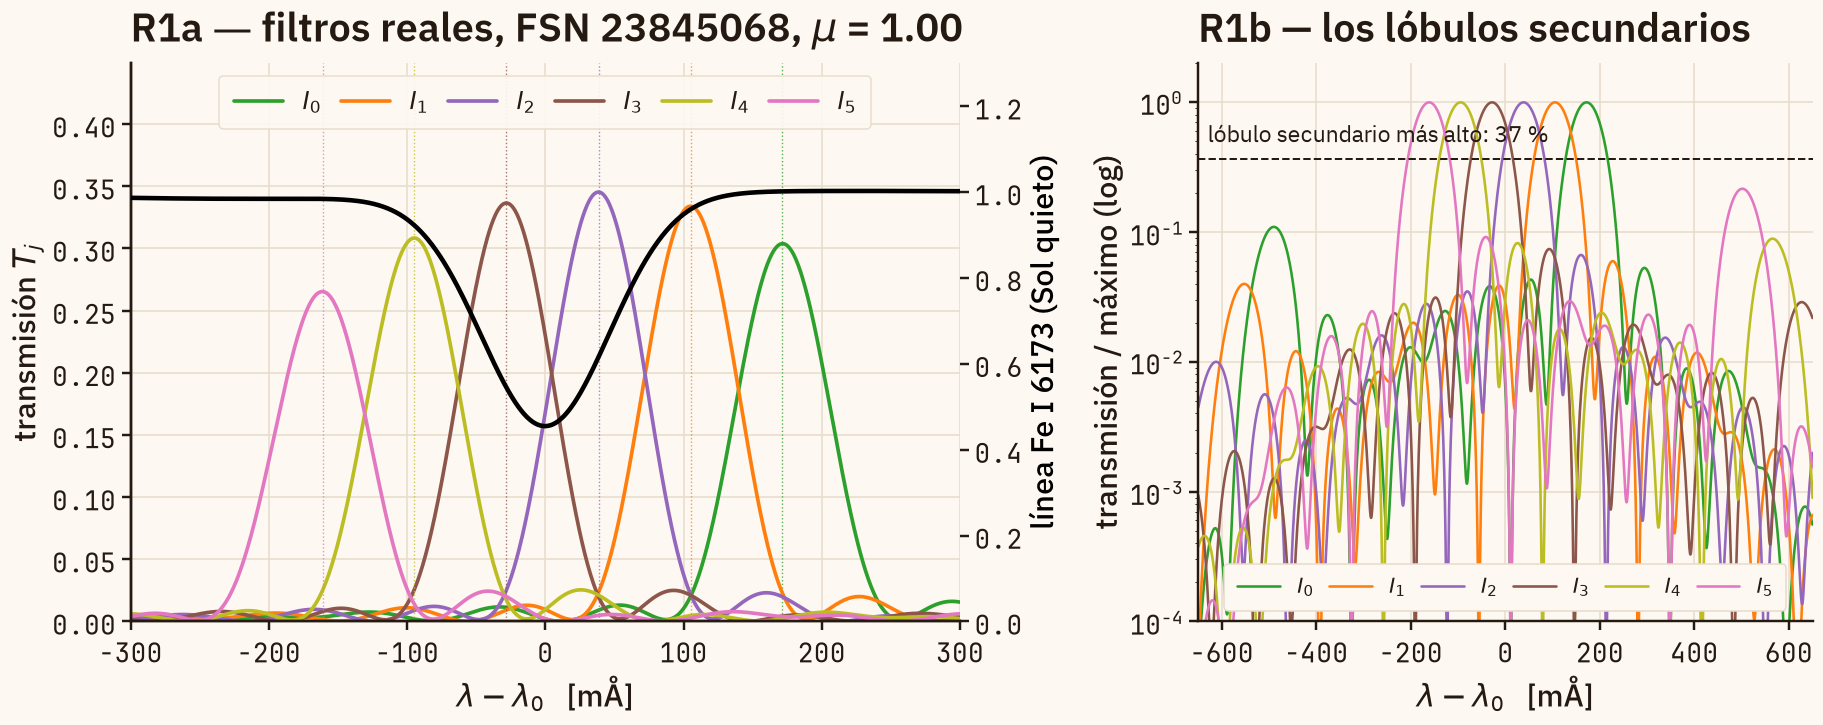

In [6]:
C_FILTERS = ['tab:green', 'tab:orange', 'tab:purple', 'tab:brown', 'tab:olive', 'tab:pink']
HALF = 0.30

fig, axes = plt.subplots(1, 2, figsize=(17, 7),
                         gridspec_kw={'width_ratios': [1.35, 1]})

ax = axes[0]
m = np.abs(fs.lam) <= HALF
for j in range(6):
    ax.plot(1e3 * fs.lam[m], fs.T[j][m], color=C_FILTERS[j], lw=LW_SERIES,
            label=f'$I_{j}$')
    ax.axvline(fs.peaks()[j], color=C_FILTERS[j], lw=0.9, ls=':', alpha=0.8)
ax.set_xlabel(r'$\lambda - \lambda_0$   [mÅ]')
ax.set_ylabel('transmisión $T_j$')
ax.set_xlim(-1e3 * HALF, 1e3 * HALF)
ax.set_ylim(0, 1.30 * fs.T[:, m].max())
ax2 = ax.twinx()
Lq1 = rl.quiet_line(fs.meta['mu'], EPOCAS[FSN_REF]['cal'])
ax2.plot(1e3 * fs.lam[m], Lq1(fs.lam[m]), color='black', lw=LW_SERIES + 0.6, zorder=5)
ax2.set_ylabel('línea Fe I 6173 (Sol quieto)', color='black')
ax2.set_ylim(0, 1.30)
ax2.grid(False)
ax.set_title(f'R1a — filtros reales, FSN {FSN_REF}, $\\mu$ = {fs.meta["mu"]:.2f}', loc='left')
ax.legend(ncols=6, loc='upper center', fontsize=FS_ANNOT + 2, columnspacing=0.8,
          bbox_to_anchor=(0.5, 1.0), framealpha=0.92)
mono_ticks(ax, ax2)

ax = axes[1]
mw = np.abs(fs.lam) <= 0.65
for j in range(6):
    ax.semilogy(fs.lam[mw] * 1e3, np.clip(fs.T[j][mw] / fs.T[j].max(), 1e-4, None),
                color=C_FILTERS[j], lw=1.7, label=f'$I_{j}$')
sec = []
for j in range(6):
    t_ = fs.T[j] / fs.T[j].max()
    lejos = np.abs(fs.lam - fs.lam[fs.T[j].argmax()]) > 0.045
    sec.append(t_[lejos & (np.abs(fs.lam) <= 0.65)].max())
sec_max = max(sec)
ax.axhline(sec_max, color=C_INK, lw=1.3, ls='--')
ax.annotate(f'lóbulo secundario más alto: {100*sec_max:.0f} %',
            xy=(-630, sec_max * 1.35), fontsize=FS_ANNOT + 1, color=C_INK)
ax.set_xlabel(r'$\lambda - \lambda_0$   [mÅ]')
ax.set_ylabel('transmisión / máximo (log)')
ax.set_xlim(-650, 650); ax.set_ylim(1e-4, 2)
ax.set_title('R1b — los lóbulos secundarios', loc='left')
ax.legend(loc='lower center', ncols=6, fontsize=FS_ANNOT, columnspacing=0.7)
mono_ticks(ax)

fig.tight_layout()
save_fig(fig, 'R1_filtros_reales')
plt.show()

### R2 — La línea del pipeline, y el archivo que **no** se usa

`HMI_lookup.c:236-240` tiene comentada la lectura de `ReferenceFeLine.bin`. La
línea de Sol quieto que el pipeline usa realmente (líneas 279-357) es

$$
L(\lambda) = I_c - f_d\, e^{-l^2}\Big[1 - a\tfrac{2}{\sqrt{\pi}}\tfrac{1}{2l^2}
\big((4l^2{+}3)(l^2{+}1)e^{-l^2} - \tfrac{1}{l^2}(2l^2{+}3)\sinh l^2\big)\Big]
+ A_1 e^{-(\lambda-c_1)^2/w_1^2} + A_2 e^{-(\lambda-c_2)^2/w_2^2}
$$

con $l = \lambda/f_w$ y parámetros por calibración (11: may 2010 – ene 2012;
12: desde ene 2012; 13: desde ene 2014). Qué calibración usó cada LUT está en su
keyword `COMMENT`.

El panel derecho muestra por qué esto importa: el perfil del `.bin` tiene su
mínimo en −62 mÅ, y usarlo sesga la velocidad aparente en ~2.4 km/s.

saved → ../figures/R2_linea_real.png


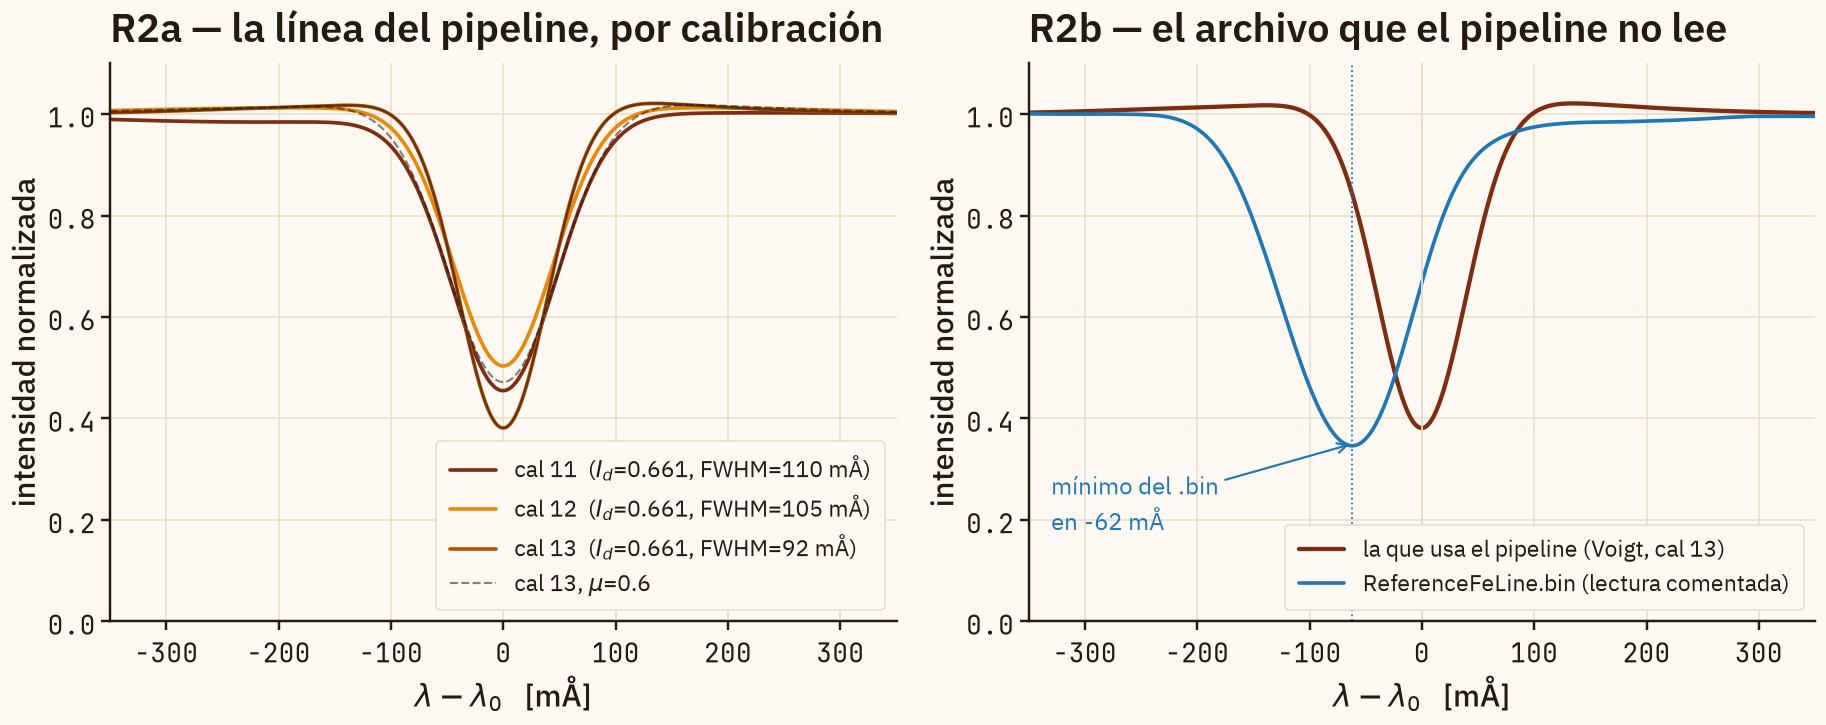

In [7]:
bin_line, bin_wl = rl.reference_bin_line()
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

ax = axes[0]
for cal, col in zip((11, 12, 13), (C_SERIES_3, C_SERIES_1, C_SERIES_4)):
    L = rl.quiet_line(1.0, cal)
    ax.plot(1e3 * L.lam_ref, L.prof, color=col, lw=LW_SERIES,
            label=f'cal {cal}  ($I_d$={L.Id:.3f}, FWHM={L.measured_fwhm():.0f} mÅ)')
for mu, ls in ((1.0, '-'), (0.6, '--')):
    L = rl.quiet_line(mu, 13)
    ax.plot(1e3 * L.lam_ref, L.prof, color=C_INK, lw=1.4, ls=ls, alpha=0.55,
            label=f'cal 13, $\\mu$={mu:.1f}' if mu != 1.0 else None)
ax.set_xlim(-350, 350); ax.set_ylim(0, 1.1)
ax.set_xlabel(r'$\lambda - \lambda_0$   [mÅ]')
ax.set_ylabel('intensidad normalizada')
ax.set_title('R2a — la línea del pipeline, por calibración', loc='left')
ax.legend(loc='lower right', fontsize=FS_ANNOT + 1)
mono_ticks(ax)

ax = axes[1]
L13 = rl.quiet_line(1.0, 13)
ax.plot(1e3 * L13.lam_ref, L13.prof, color=C_SERIES_3, lw=LW_SERIES + 0.4,
        label='la que usa el pipeline (Voigt, cal 13)')
ax.plot(1e3 * bin_wl, bin_line, color='tab:blue', lw=LW_SERIES,
        label='ReferenceFeLine.bin (lectura comentada)')
ax.axvline(0, color=C_GRID, lw=1.2)
ax.axvline(1e3 * bin_wl[bin_line.argmin()], color='tab:blue', lw=1.2, ls=':')
ax.annotate(f'mínimo del .bin\nen {1e3*bin_wl[bin_line.argmin()]:+.0f} mÅ',
            xy=(1e3 * bin_wl[bin_line.argmin()], 0.35), xytext=(-330, 0.18),
            color='tab:blue', fontsize=FS_ANNOT + 2,
            arrowprops=dict(arrowstyle='->', color='tab:blue', lw=1.4))
ax.set_xlim(-350, 350); ax.set_ylim(0, 1.1)
ax.set_xlabel(r'$\lambda - \lambda_0$   [mÅ]')
ax.set_ylabel('intensidad normalizada')
ax.set_title('R2b — el archivo que el pipeline no lee', loc='left')
ax.legend(loc='lower right', fontsize=FS_ANNOT + 1)
mono_ticks(ax)

fig.tight_layout()
save_fig(fig, 'R2_linea_real')
plt.show()

## §4 — Validación: ¿reproducimos la LUT real del JSOC?

Esta es la prueba que decide si todo lo anterior está bien. Se construye la
curva $v_{\rm aparente}(v_{\rm test})$ con nuestros filtros y nuestra línea, y
se compara con el corte correspondiente de `lookup.fits`, la tabla que el
pipeline realmente usó.

### Pseudocódigo de la cadena forward y de la reconstrucción

```
intensities(filtros, linea, v):          # HMI_lookup.c:1117
    recorta maxshiftlam muestras en cada borde de la rejilla
    L_k  = linea(lam_k - v*dlamdv)       # v>0 = corrimiento al rojo
    I_j  = suma_k T_j,k * L_k

velocities_from_intensities(I):          # HMI_lookup.c:1124-1141
    angle_j = [2.5, 1.5, 0.5, -0.5, -1.5, -2.5] * 2 pi / 6
    f1c = suma I_j cos(angle_j) ;  f1s = suma I_j sin(angle_j)
    vel1 = atan2(-f1s, -f1c) * pv1 / 2 pi
    f2c, f2s analogos ;  vel2 = atan2(-f2s,-f2c)*pv2/2pi, desenvuelta vs vel1

ReconstructedLUT(filtros):
    vtest   = 24 * (i - 410),  i = 0..820
    vapp[i] = vel1(linea_quieta(mu, cal), vtest[i])

JSOCLookupTable(fsn, fila, col):
    vapp = lookup.fits[0:821, fila, col]          # el 1er armonico
```

Y la inversión, como `Dopplergram.c:482-585`:

```
__call__(vapp):
    si vapp fuera de [vapp[0], vapp[-1]]:  recorta al extremo y cuenta SATVALS
    si no: busca el intervalo que lo encierra e interpola linealmente -> v_true
```

In [8]:
VAL = {}
vt = jd.vtest_grid()
for fsn, info in EPOCAS.items():
    lut_real, rec = jd.load_real_lut(fsn)
    fila = {}
    for nombre, (r, c) in [('centro', PIX_CENTRO), ('mu~0.6', PIX_LIMBO)]:
        f_ = rfl.build_filters(fsn, r, c)
        mu = f_.meta['mu']
        mia = rp.apparent_velocity(f_, rl.quiet_line(mu, info['cal']), vt)
        real = np.asarray(lut_real[:len(vt), r, c], float)
        fila[nombre] = dict(mu=mu, mia=mia, real=real, pix=(r, c))
    VAL[fsn] = fila
    del lut_real

print('rms de la reconstruccion contra la LUT real del JSOC')
print(f'{"FSN":>10} {"fecha":>12} {"cal":>4} {"pixel":>10} {"mu":>6} '
      f'{"rms total":>10} {"rms |v|<5km/s":>14} {"max":>8}')
for fsn, fila in VAL.items():
    for nombre, d in fila.items():
        dif = d['mia'] - d['real']
        m = np.abs(vt) < 5000
        print(f'{fsn:>10} {EPOCAS[fsn]["fecha"]:>12} {EPOCAS[fsn]["cal"]:>4} '
              f'{str(d["pix"]):>10} {d["mu"]:6.3f} {np.sqrt(np.mean(dif**2)):9.1f}  '
              f'{np.sqrt(np.mean(dif[m]**2)):13.1f}  {np.abs(dif).max():7.1f}   [m/s]')

# la calibracion correcta se puede identificar a ciegas desde el residual
print('\nDiscriminacion de la calibracion (FSN 23845068, pixel central):')
d = VAL[FSN_REF]['centro']
for cal in (11, 12, 13):
    mia = rp.apparent_velocity(rfl.build_filters(FSN_REF, *PIX_CENTRO),
                               rl.quiet_line(d['mu'], cal), vt)
    marca = '  <- la que declara el COMMENT' if cal == EPOCAS[FSN_REF]['cal'] else ''
    print(f'  cal {cal}: rms = {np.sqrt(np.mean((mia - d["real"])**2)):7.1f} m/s{marca}')

rms de la reconstruccion contra la LUT real del JSOC
       FSN        fecha  cal      pixel     mu  rms total  rms |v|<5km/s      max
  23845068   2011-06-22   11   (64, 64)  1.000       3.3            3.8      4.7   [m/s]
  23845068   2011-06-22   11   (64, 15)  0.600      28.4           34.0     35.8   [m/s]
  65714753   2013-12-18   13   (64, 64)  1.000      12.7           14.8     15.6   [m/s]
  65714753   2013-12-18   13   (64, 15)  0.600      40.7           48.1     49.6   [m/s]
 104314890   2016-04-05   13   (64, 64)  1.000      11.4           13.2     13.7   [m/s]
 104314890   2016-04-05   13   (64, 15)  0.600      16.1           19.0     19.6   [m/s]

Discriminacion de la calibracion (FSN 23845068, pixel central):
  cal 11: rms =     3.3 m/s  <- la que declara el COMMENT


  cal 12: rms =    80.5 m/s
  cal 13: rms =   205.7 m/s


### R3 — Reconstruida contra real

saved → ../figures/R3_validacion_lut.png


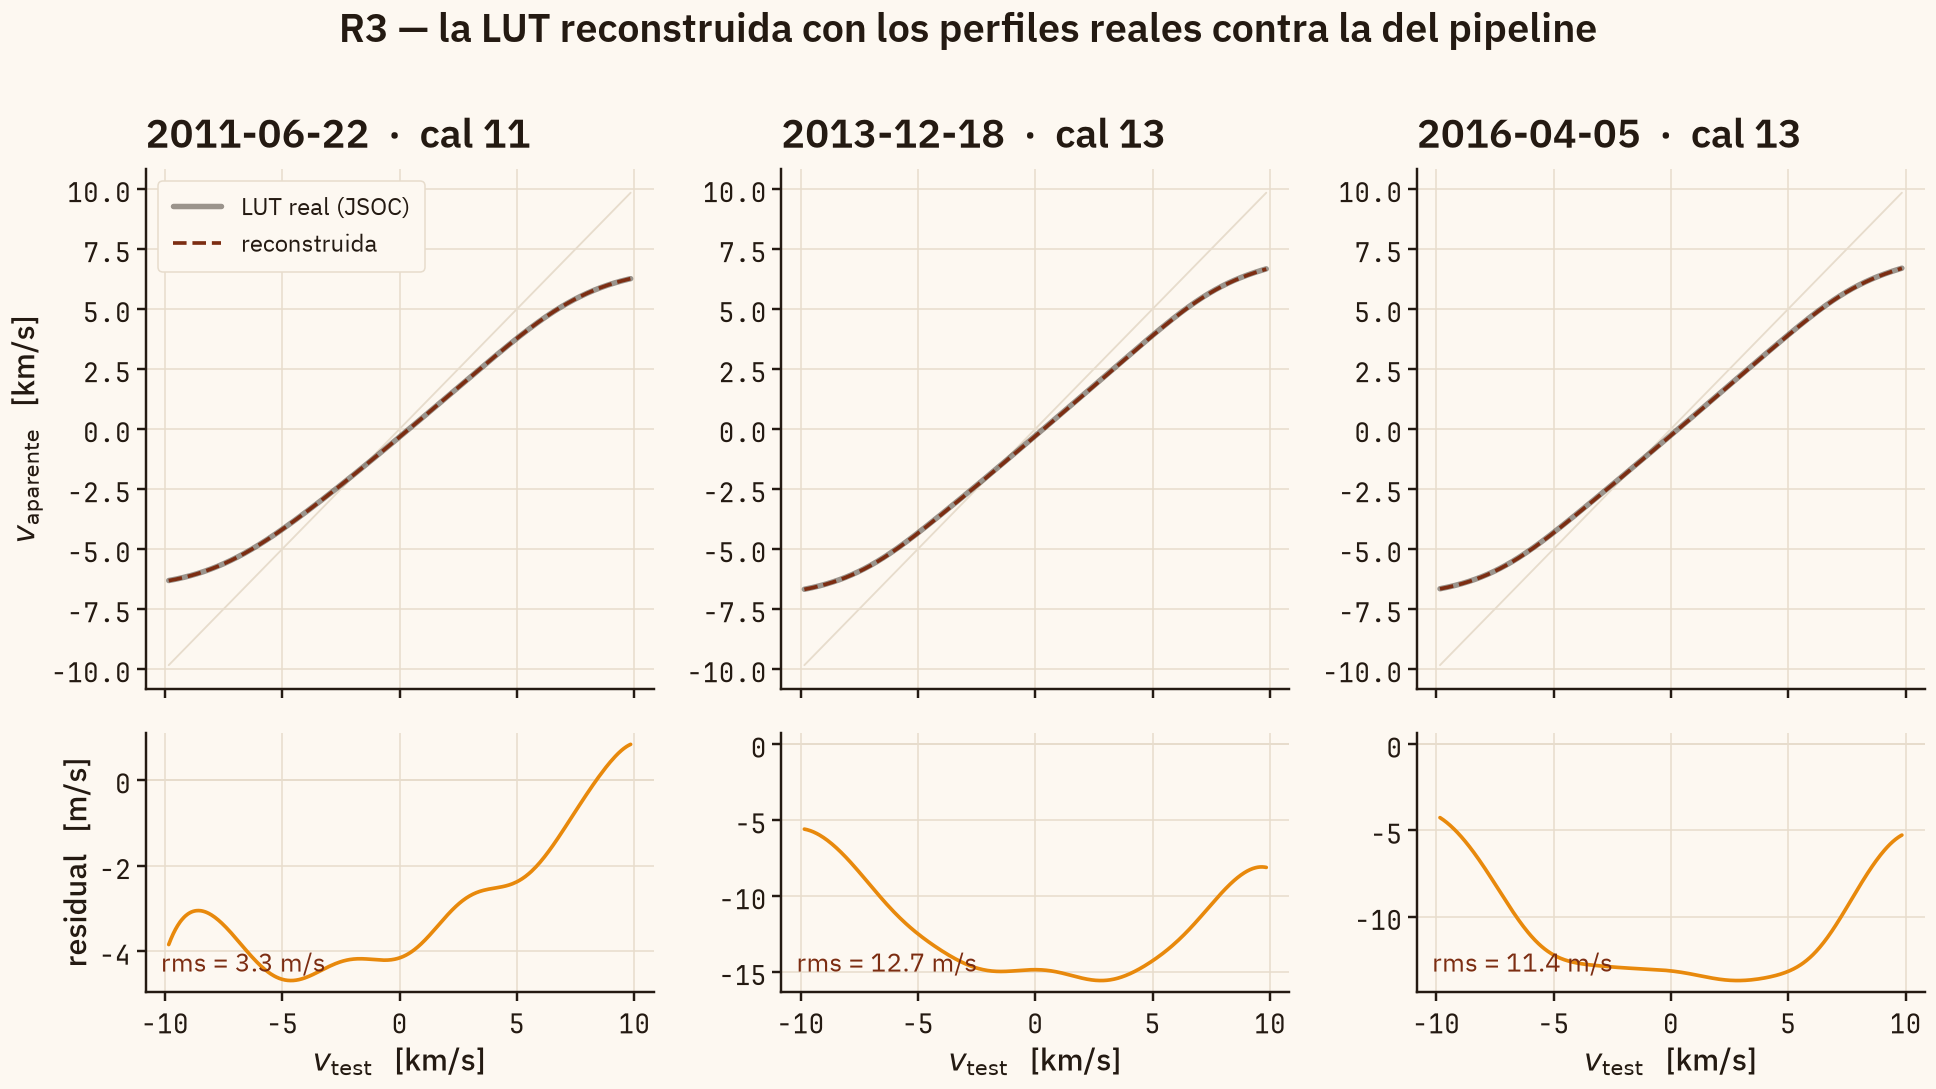

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]})
for k, (fsn, fila) in enumerate(VAL.items()):
    d = fila['centro']
    ax = axes[0, k]
    ax.plot(vt / 1e3, d['real'] / 1e3, color=C_INK, lw=LW_SERIES + 1.2,
            alpha=0.45, label='LUT real (JSOC)')
    ax.plot(vt / 1e3, d['mia'] / 1e3, color=C_SERIES_3, lw=LW_SERIES, ls='--',
            label='reconstruida')
    ax.plot(vt / 1e3, vt / 1e3, color=C_GRID, lw=1.2, zorder=0)
    ax.set_title(f'{EPOCAS[fsn]["fecha"]}  ·  cal {EPOCAS[fsn]["cal"]}', loc='left')
    if k == 0:
        ax.set_ylabel('$v_{\\rm aparente}$   [km/s]')
        ax.legend(loc='upper left', fontsize=FS_ANNOT + 2)
    mono_ticks(ax)

    ax = axes[1, k]
    ax.axhline(0, color=C_GRID, lw=1.2)
    ax.plot(vt / 1e3, d['mia'] - d['real'], color=C_SERIES_1, lw=LW_SERIES)
    ax.set_xlabel('$v_{\\rm test}$   [km/s]')
    rms = np.sqrt(np.mean((d['mia'] - d['real']) ** 2))
    ax.annotate(f'rms = {rms:.1f} m/s', xy=(0.03, 0.08), xycoords='axes fraction',
                fontsize=FS_ANNOT + 3, color=C_SERIES_3)
    if k == 0:
        ax.set_ylabel('residual   [m/s]')
    mono_ticks(ax)

fig.suptitle('R3 — la LUT reconstruida con los perfiles reales contra la del pipeline',
             fontsize=FS_TITLE, y=1.0)
fig.tight_layout()
save_fig(fig, 'R3_validacion_lut')
plt.show()

## §5 — Experimento A: validación de la cadena completa

Con `z_W = 0` y `B = 0` la línea umbral se reduce exactamente a la quieta, así
que el pipeline tiene que devolver la velocidad que se le puso, para cualquier
`v_true` y cualquier `OBS_VR`. El residual que quede es el piso de ruido del
modelo, y hay que compararlo con el paso de la tabla, `dvtest = 24 m/s`.

### Pseudocódigo de `real_artifact.RealPipeline.observables`

```
observables(z_W, B, v_true, obs_vr, zeeman, gamma, estimator):
    v_shift = v_true + obs_vr
    L_lcp = linea_real(z_W, B, 'LCP')       # Wilson + Zeeman
    L_rcp = linea_real(z_W, B, 'RCP')
    vapp_L = 1er Fourier de la integral por los filtros reales en v_shift
    vapp_R = idem
    v_L, v_R = LUT_quieta(vapp_L), LUT_quieta(vapp_R)    # aqui esta el error
    V      = (v_L + v_R)/2                               # Couvidat Ec. 14
    B_los  = (v_L - v_R) * Km                            # Couvidat Ec. 15
    artefacto     = V - v_shift
    artefacto_rel = V - V(Sol quieto, mismo v_shift)     # Sol quieto sustraido
```

`estimator` elige qué parte de la cadena se usa, y es lo que permite separar las
contribuciones:

| `estimator` | muestreo | inversión | para qué sirve |
|---|---|---|---|
| `'pipeline'` | filtros reales | LUT quieta | lo que HMI hace |
| `'raw'` | filtros reales | ninguna | cuánto aporta la tabla |
| `'delta'` | deltas en los picos | LUT equivalente | lo que cancelaría un instrumento ideal |

In [10]:
PIPES = {fsn: ra.RealPipeline(fsn, *PIX_CENTRO) for fsn in EPOCAS}
P = PIPES[FSN_REF]
print(P)
print(f'rango de la LUT: [{P.lut.vmin:.0f}, {P.lut.vmax:.0f}] m/s'
      f'   (pv1/2 = {rp.velocity_scale()[2]/2:.0f})')

v_true = np.linspace(-4000, 4000, 81)
A = {}
for ov in (0.0, 1500.0, 3000.0, -3000.0):
    o = P.observables(0.0, 0.0, v_true, ov)
    A[ov] = o
    print(f'  OBS_VR = {ov:+7.0f} m/s:  |artefacto| max = {np.abs(o["artifact"]).max():5.2f} m/s'
          f'   |B_LOS| max = {np.abs(o["B_los"]).max():.3f} G   saturados = {o["saturated"]}')
print(f'\npaso de la rejilla de la LUT (piso de resolucion): {jd.parse_hmiparam()["dvtest"]:.0f} m/s')

<RealPipeline FSN 23845068 (64,64) mu=1.000 cal=11 lut=jsoc>
rango de la LUT: [-6315, 6260] m/s   (pv1/2 = 8202)
  OBS_VR =      +0 m/s:  |artefacto| max =  6.27 m/s   |B_LOS| max = 0.000 G   saturados = 0
  OBS_VR =   +1500 m/s:  |artefacto| max =  5.45 m/s   |B_LOS| max = 0.000 G   saturados = 0


  OBS_VR =   +3000 m/s:  |artefacto| max =  5.21 m/s   |B_LOS| max = 0.000 G   saturados = 0
  OBS_VR =   -3000 m/s:  |artefacto| max =  7.42 m/s   |B_LOS| max = 0.000 G   saturados = 0

paso de la rejilla de la LUT (piso de resolucion): 24 m/s


saved → ../figures/R4_expA_validacion.png


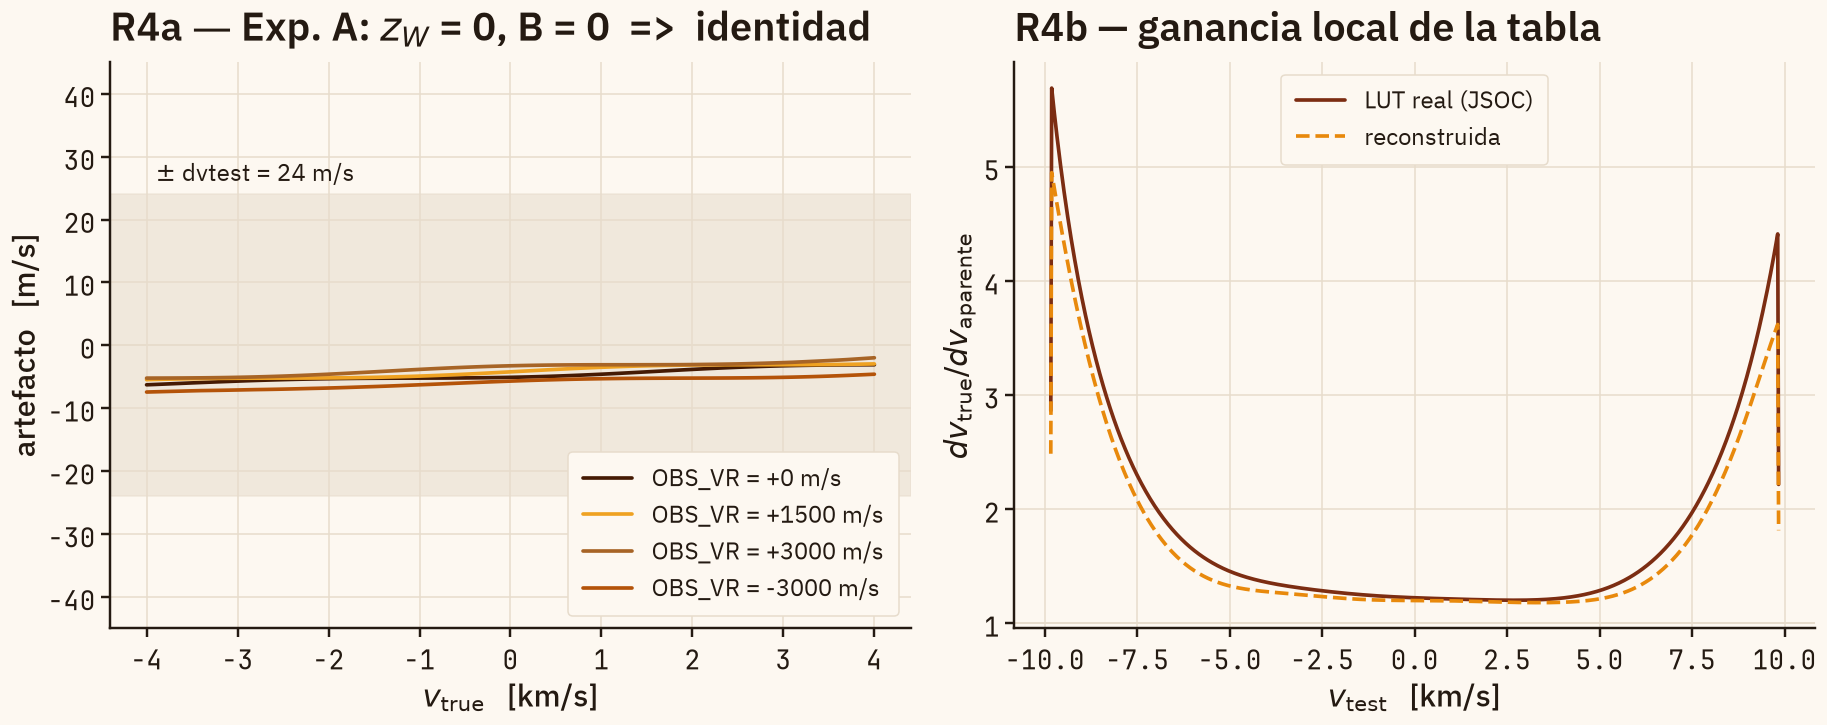

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

ax = axes[0]
ax.axhline(0, color=C_GRID, lw=1.2)
for k, (ov, o) in enumerate(A.items()):
    ax.plot(v_true / 1e3, o['artifact'], lw=LW_SERIES,
            color=CMAP_AMBER(k / (len(A) - 1)), label=f'OBS_VR = {ov:+.0f} m/s')
ax.axhspan(-24, 24, color=C_GRID, alpha=0.55, zorder=0)
ax.annotate('$\\pm$ dvtest = 24 m/s', xy=(-3.9, 26), fontsize=FS_ANNOT + 2, color=C_INK)
ax.set_xlabel('$v_{\\rm true}$   [km/s]')
ax.set_ylabel('artefacto   [m/s]')
ax.set_ylim(-45, 45)
ax.set_title('R4a — Exp. A: $z_W$ = 0, B = 0  =>  identidad', loc='left')
ax.legend(loc='lower right', fontsize=FS_ANNOT + 2)
mono_ticks(ax)

ax = axes[1]
ax.plot(vt / 1e3, P.lut.gain(), color=C_SERIES_3, lw=LW_SERIES,
        label='LUT real (JSOC)')
ax.plot(vt / 1e3, rp.ReconstructedLUT(P.filters, mu=P.mu).gain(),
        color=C_SERIES_1, lw=LW_SERIES, ls='--', label='reconstruida')
ax.axhline(1.0, color=C_GRID, lw=1.2)
ax.set_xlabel('$v_{\\rm test}$   [km/s]')
ax.set_ylabel('$dv_{\\rm true}/dv_{\\rm aparente}$')
ax.set_title('R4b — ganancia local de la tabla', loc='left')
ax.legend(loc='upper center', fontsize=FS_ANNOT + 2)
mono_ticks(ax)

fig.tight_layout()
save_fig(fig, 'R4_expA_validacion')
plt.show()

## §6 — Experimento B: el artefacto contra la profundidad de Wilson

Ahora se enciende la deformación. La depresión de Wilson se aplica sobre la
línea **real** con los mismos factores que ya tenía `profiles.wilson_parameters`,
de modo que las perillas de `config.py` siguen significando lo mismo:

$$L_u(\lambda) = I_c f_c - f_d\, D\!\left(\frac{\lambda - \lambda_{\rm centro}}{f_s}\right),
\qquad (f_c, f_d, f_s) = (1 - k_c z_W,\ 1 - k_d z_W,\ 1 - k_s z_W)$$

Se grafica el artefacto **relativo al Sol quieto**, que es lo comparable con las
observaciones (que ya lo tienen sustraído).

In [12]:
z = np.linspace(0.0, 800.0, 41)
OBS_NIVELES = [0.0, 1000.0, 2000.0, 3000.0]

B_cur = {ov: np.array([P.observables(zi, cfg.B_GAUSS, 0.0, ov)['artifact_rel'][0]
                       for zi in z]) for ov in OBS_NIVELES}
B_epo = {fsn: np.array([pp.observables(zi, cfg.B_GAUSS, 0.0, 3000.0)['artifact_rel'][0]
                        for zi in z]) for fsn, pp in PIPES.items()}
# descomposicion a OBS_VR = 3000
solo_wilson = np.array([P.observables(zi, 0.0, 0.0, 3000.0)['artifact_rel'][0] for zi in z])
solo_zeeman = P.observables(0.0, cfg.B_GAUSS, 0.0, 3000.0)['artifact_rel'][0]

print(f'B = {cfg.B_GAUSS:.0f} G,  artefacto relativo al Sol quieto  [m/s]')
print(f'{"z_W [km]":>9}' + ''.join(f'{f"OBS_VR={ov:.0f}":>16}' for ov in OBS_NIVELES))
for zi in (0, 200, 400, 600, 800):
    i = int(np.argmin(np.abs(z - zi)))
    print(f'{z[i]:9.0f}' + ''.join(f'{B_cur[ov][i]:16.1f}' for ov in OBS_NIVELES))
pend = np.polyfit(z, B_cur[3000.0], 1)[0]
print(f'\npendiente a OBS_VR = 3000 m/s: {pend:.3f} (m/s) por km de z_W')
print(f'solo Wilson (B=0, z_W=600):   {solo_wilson[np.argmin(np.abs(z-600))]:+8.1f} m/s')
print(f'solo Zeeman (z_W=0, B=2500):  {solo_zeeman:+8.1f} m/s')
print(f'los dos juntos (600, 2500):   {B_cur[3000.0][np.argmin(np.abs(z-600))]:+8.1f} m/s')

B = 2500 G,  artefacto relativo al Sol quieto  [m/s]
 z_W [km]        OBS_VR=0     OBS_VR=1000     OBS_VR=2000     OBS_VR=3000
        0             0.1             0.1             0.1             0.6
      200            -8.7             6.5            21.8            38.4
      400           -17.9            12.3            43.1            76.0
      600           -27.5            17.6            63.7           113.3
      800           -37.7            21.9            83.3           149.9

pendiente a OBS_VR = 3000 m/s: 0.187 (m/s) por km de z_W
solo Wilson (B=0, z_W=600):       -4.0 m/s
solo Zeeman (z_W=0, B=2500):      +0.6 m/s
los dos juntos (600, 2500):     +113.3 m/s


saved → ../figures/R5_expB_wilson.png


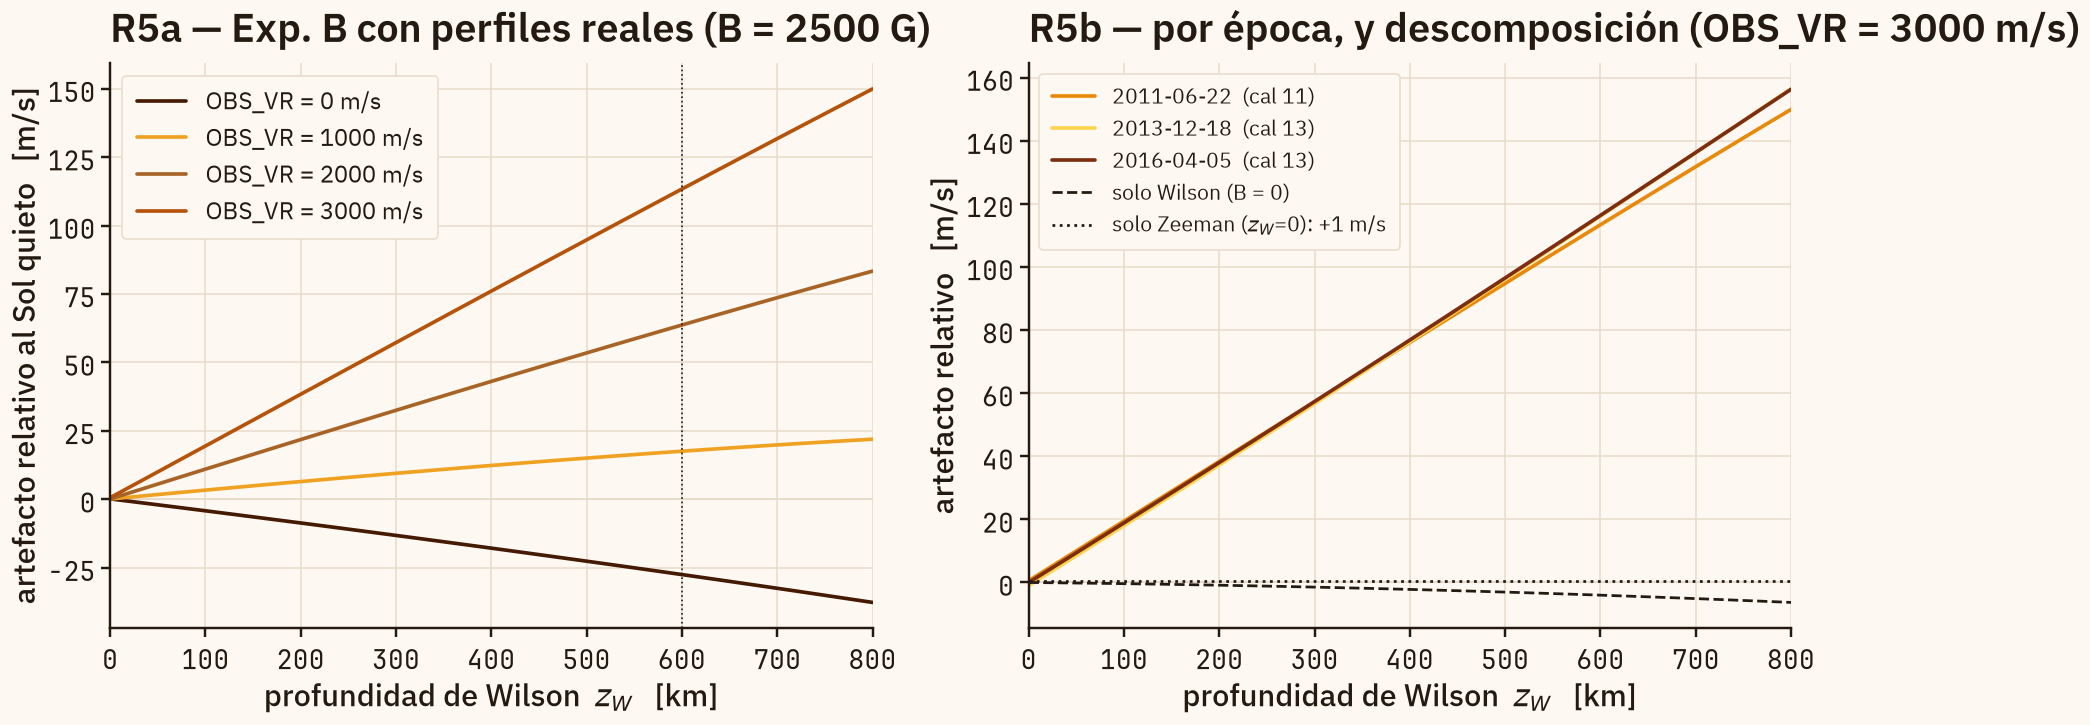

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

ax = axes[0]
ax.axhline(0, color=C_GRID, lw=1.2)
for k, ov in enumerate(OBS_NIVELES):
    ax.plot(z, B_cur[ov], lw=LW_SERIES, color=CMAP_AMBER(k / (len(OBS_NIVELES) - 1)),
            label=f'OBS_VR = {ov:.0f} m/s')
ax.axvline(cfg.Z_W_REF, color=C_INK, lw=1.1, ls=':')
ax.set_xlabel('profundidad de Wilson  $z_W$   [km]')
ax.set_ylabel('artefacto relativo al Sol quieto   [m/s]')
ax.set_xlim(z[0], z[-1])
ax.set_title(f'R5a — Exp. B con perfiles reales (B = {cfg.B_GAUSS:.0f} G)', loc='left')
ax.legend(loc='upper left', fontsize=FS_ANNOT + 2)
mono_ticks(ax)

ax = axes[1]
ax.axhline(0, color=C_GRID, lw=1.2)
for k, (fsn, cur) in enumerate(B_epo.items()):
    ax.plot(z, cur, lw=LW_SERIES, color=PALETTE[k % 4],
            label=f'{EPOCAS[fsn]["fecha"]}  (cal {EPOCAS[fsn]["cal"]})')
ax.plot(z, solo_wilson, color=C_INK, lw=1.8, ls='--', label='solo Wilson (B = 0)')
ax.axhline(solo_zeeman, color=C_INK, lw=1.8, ls=':',
           label=f'solo Zeeman ($z_W$=0): {solo_zeeman:+.0f} m/s')
ax.set_xlabel('profundidad de Wilson  $z_W$   [km]')
ax.set_ylabel('artefacto relativo   [m/s]')
ax.set_xlim(z[0], z[-1])
ax.set_title('R5b — por época, y descomposición (OBS_VR = 3000 m/s)', loc='left')
ax.legend(loc='upper left', fontsize=FS_ANNOT)
mono_ticks(ax)

fig.tight_layout()
save_fig(fig, 'R5_expB_wilson')
plt.show()

## §7 — Experimento C: la firma de 24 h

`OBS_VR(t)` es la velocidad radial SDO–Sol, dominada por la órbita
geosincrónica. Con una sinusoide de 24 h y 3 km/s de amplitud se barre el
artefacto en el tiempo. Se comparan los tres estimadores para ver qué parte de
la amplitud pone cada eslabón.

In [14]:
t = np.linspace(0.0, 48.0, 1153)
obs = ra.orbital_obs_vr(t)

C_est = {}
for est in ('pipeline', 'raw', 'delta'):
    C_est[est] = P.observables(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, obs, estimator=est)

C_epo = {fsn: pp.observables(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, obs)
         for fsn, pp in PIPES.items()}

def amp(a):
    return 0.5 * (np.max(a) - np.min(a))

print(f'z_W = {cfg.Z_W_REF:.0f} km, B = {cfg.B_GAUSS:.0f} G, OBS_VR = '
      f'{cfg.A_ORB:.0f}*sin(2pi t/{cfg.P_ORB_HOURS:.0f}h)\n')
print(f'{"estimador":>10} {"semiamplitud":>13} {"pico-pico":>11} {"media":>9} {"saturados":>10}')
for est, o in C_est.items():
    a = o['artifact_rel']
    print(f'{est:>10} {amp(a):12.1f}  {np.ptp(a):10.1f}  {a.mean():+8.1f}  {o["saturated"]:9d}   [m/s]')
print(f'\n{"epoca":>12} {"cal":>4} {"semiamplitud":>13}')
for fsn, o in C_epo.items():
    print(f'{EPOCAS[fsn]["fecha"]:>12} {EPOCAS[fsn]["cal"]:>4} {amp(o["artifact_rel"]):12.1f}   [m/s]')
print(f'\nresidual observado de referencia: +-{cfg.V_OBSERVED_RESIDUAL:.0f} m/s')

z_W = 600 km, B = 2500 G, OBS_VR = 3000*sin(2pi t/24h)

 estimador  semiamplitud   pico-pico     media  saturados
  pipeline        161.5       322.9     -37.1          0   [m/s]
       raw        413.0       826.0    +107.6          0   [m/s]
     delta        235.5       471.0     -37.0          0   [m/s]

       epoca  cal  semiamplitud
  2011-06-22   11        161.5   [m/s]
  2013-12-18   13        144.8   [m/s]
  2016-04-05   13        145.5   [m/s]

residual observado de referencia: +-350 m/s


saved → ../figures/R6_expC_24h.png


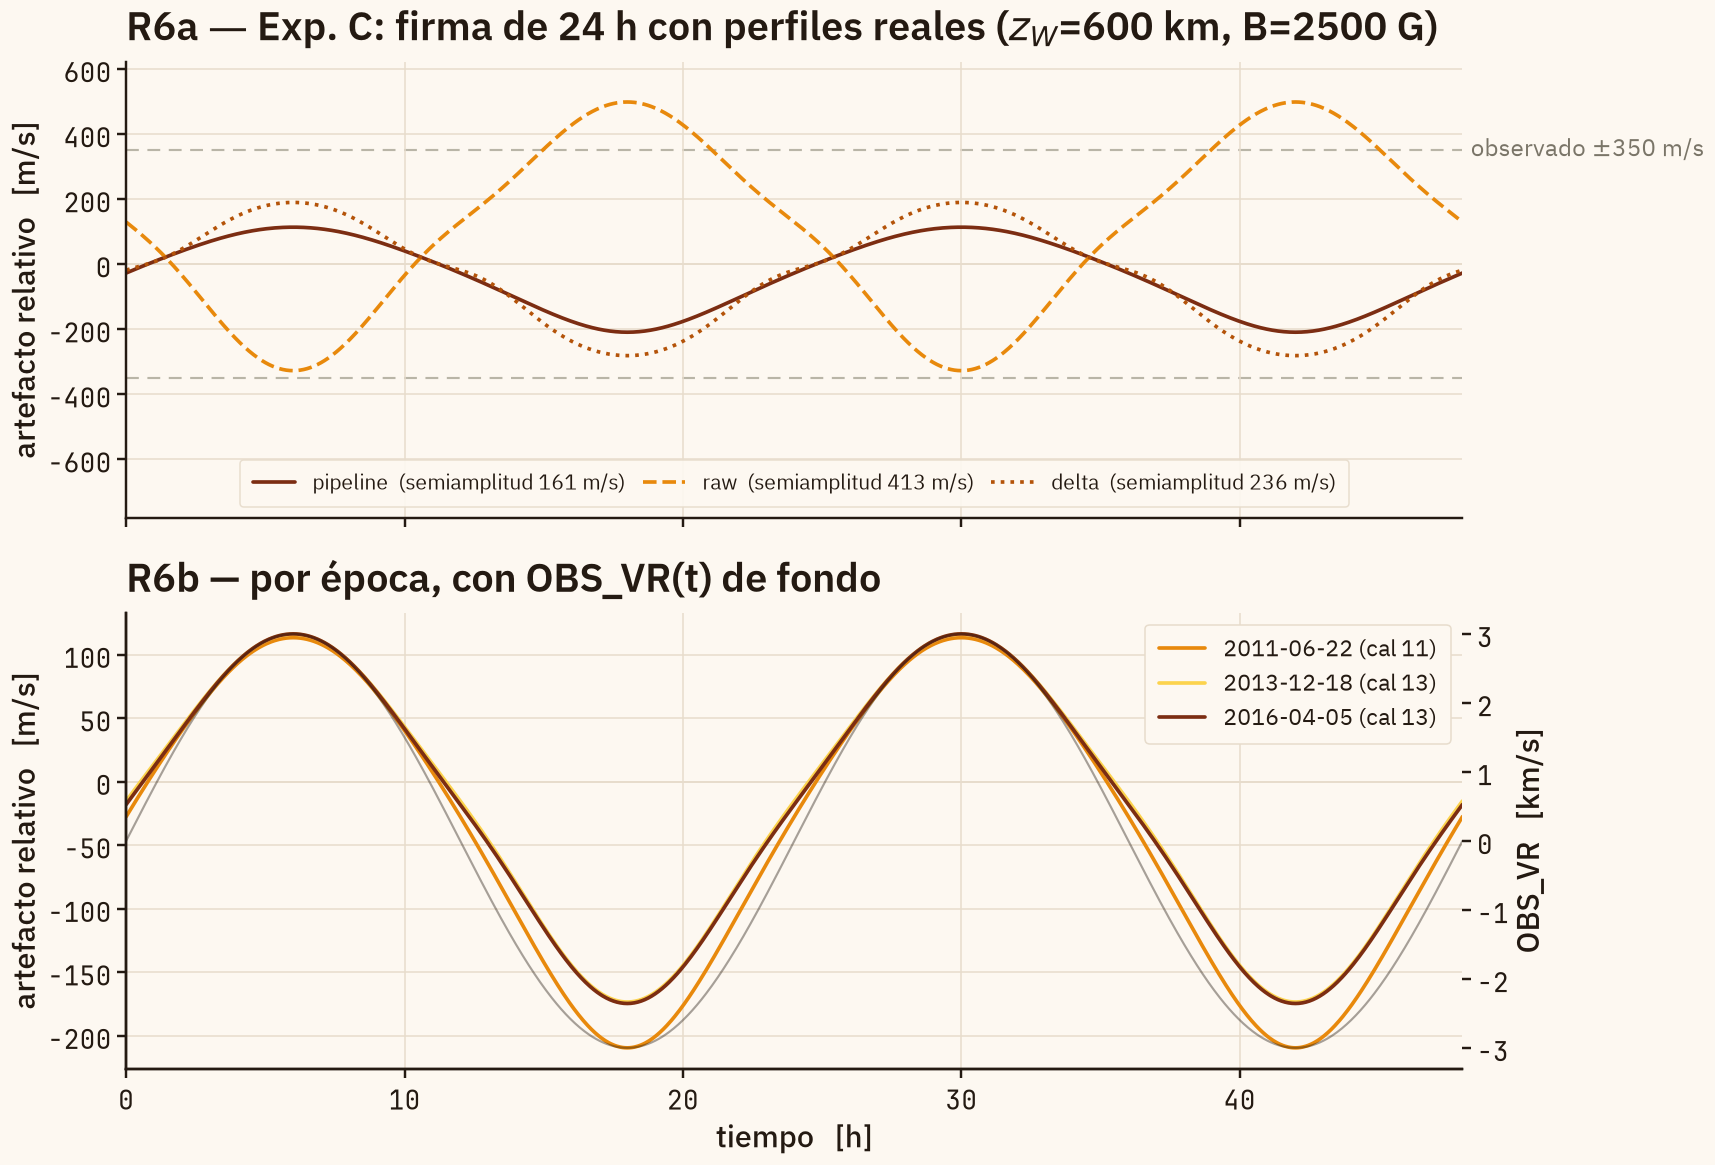

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

ax = axes[0]
for v in (-cfg.V_OBSERVED_RESIDUAL, cfg.V_OBSERVED_RESIDUAL):
    ax.axhline(v, color='#b9b5a7', lw=1.4, ls=(0, (6, 4)), zorder=0)
ax.annotate(f'observado $\\pm${cfg.V_OBSERVED_RESIDUAL:.0f} m/s',
            xy=(48.3, cfg.V_OBSERVED_RESIDUAL), fontsize=FS_ANNOT + 2,
            color='#7a7568', va='center', annotation_clip=False)
ax.axhline(0, color=C_GRID, lw=1.2)
estilos = {'pipeline': (C_SERIES_3, '-'), 'raw': (C_SERIES_1, '--'), 'delta': (C_SERIES_4, ':')}
for est, o in C_est.items():
    col, ls = estilos[est]
    ax.plot(t, o['artifact_rel'], color=col, ls=ls, lw=LW_SERIES,
            label=f'{est}  (semiamplitud {amp(o["artifact_rel"]):.0f} m/s)')
ax.set_ylabel('artefacto relativo   [m/s]')
ax.set_ylim(-780, 620)
ax.set_title(f'R6a — Exp. C: firma de 24 h con perfiles reales '
             f'($z_W$={cfg.Z_W_REF:.0f} km, B={cfg.B_GAUSS:.0f} G)', loc='left')
ax.legend(loc='lower center', ncols=3, fontsize=FS_ANNOT, columnspacing=0.8,
          framealpha=0.92)
mono_ticks(ax)

ax = axes[1]
ax.axhline(0, color=C_GRID, lw=1.2)
axb = ax.twinx()
axb.plot(t, obs / 1e3, color=C_INK, lw=1.4, alpha=0.4)
axb.set_ylabel('OBS_VR   [km/s]', color=C_INK)
axb.grid(False)
for k, (fsn, o) in enumerate(C_epo.items()):
    ax.plot(t, o['artifact_rel'], color=PALETTE[k % 4], lw=LW_SERIES,
            label=f'{EPOCAS[fsn]["fecha"]} (cal {EPOCAS[fsn]["cal"]})')
ax.set_xlabel('tiempo   [h]')
ax.set_ylabel('artefacto relativo   [m/s]')
ax.set_xlim(0, 48)
ax.set_title('R6b — por época, con OBS_VR(t) de fondo', loc='left')
ax.legend(loc='upper right', fontsize=FS_ANNOT + 1)
mono_ticks(ax, axb)

fig.tight_layout()
save_fig(fig, 'R6_expC_24h')
plt.show()

### R6c — Dopplergrama y magnetograma simulados (valores estándar)

Lo que mediría HMI en un píxel umbral a lo largo de 48 h, con los valores de
referencia de `config.py` y la cadena real completa (filtros del día, línea del
pipeline, LUT del JSOC):

| parámetro | valor |
|---|---|
| profundidad de Wilson $z_W$ | `Z_W_REF` = 600 km |
| campo longitudinal $B$ | `B_GAUSS` = 2500 G |
| `OBS_VR(t)` | `A_ORB`·sin(2πt / `P_ORB_HOURS`) = 3000 m/s, 24 h |
| Zeeman | corrimiento rígido ($\gamma = 0$) |
| estimador | `pipeline` (filtros reales + LUT real) |
| época / píxel | FSN 23845068, píxel central ($\mu \approx 1$) |

Arriba el dopplerograma (artefacto relativo al Sol quieto, $V - V_{\rm quieto}$);
abajo el magnetograma ($B_{\rm LOS} = (v_{\rm LCP} - v_{\rm RCP})\,K_m$) contra
el campo real.

saved → ../figures/R6c_dopplergrama_magnetograma.png


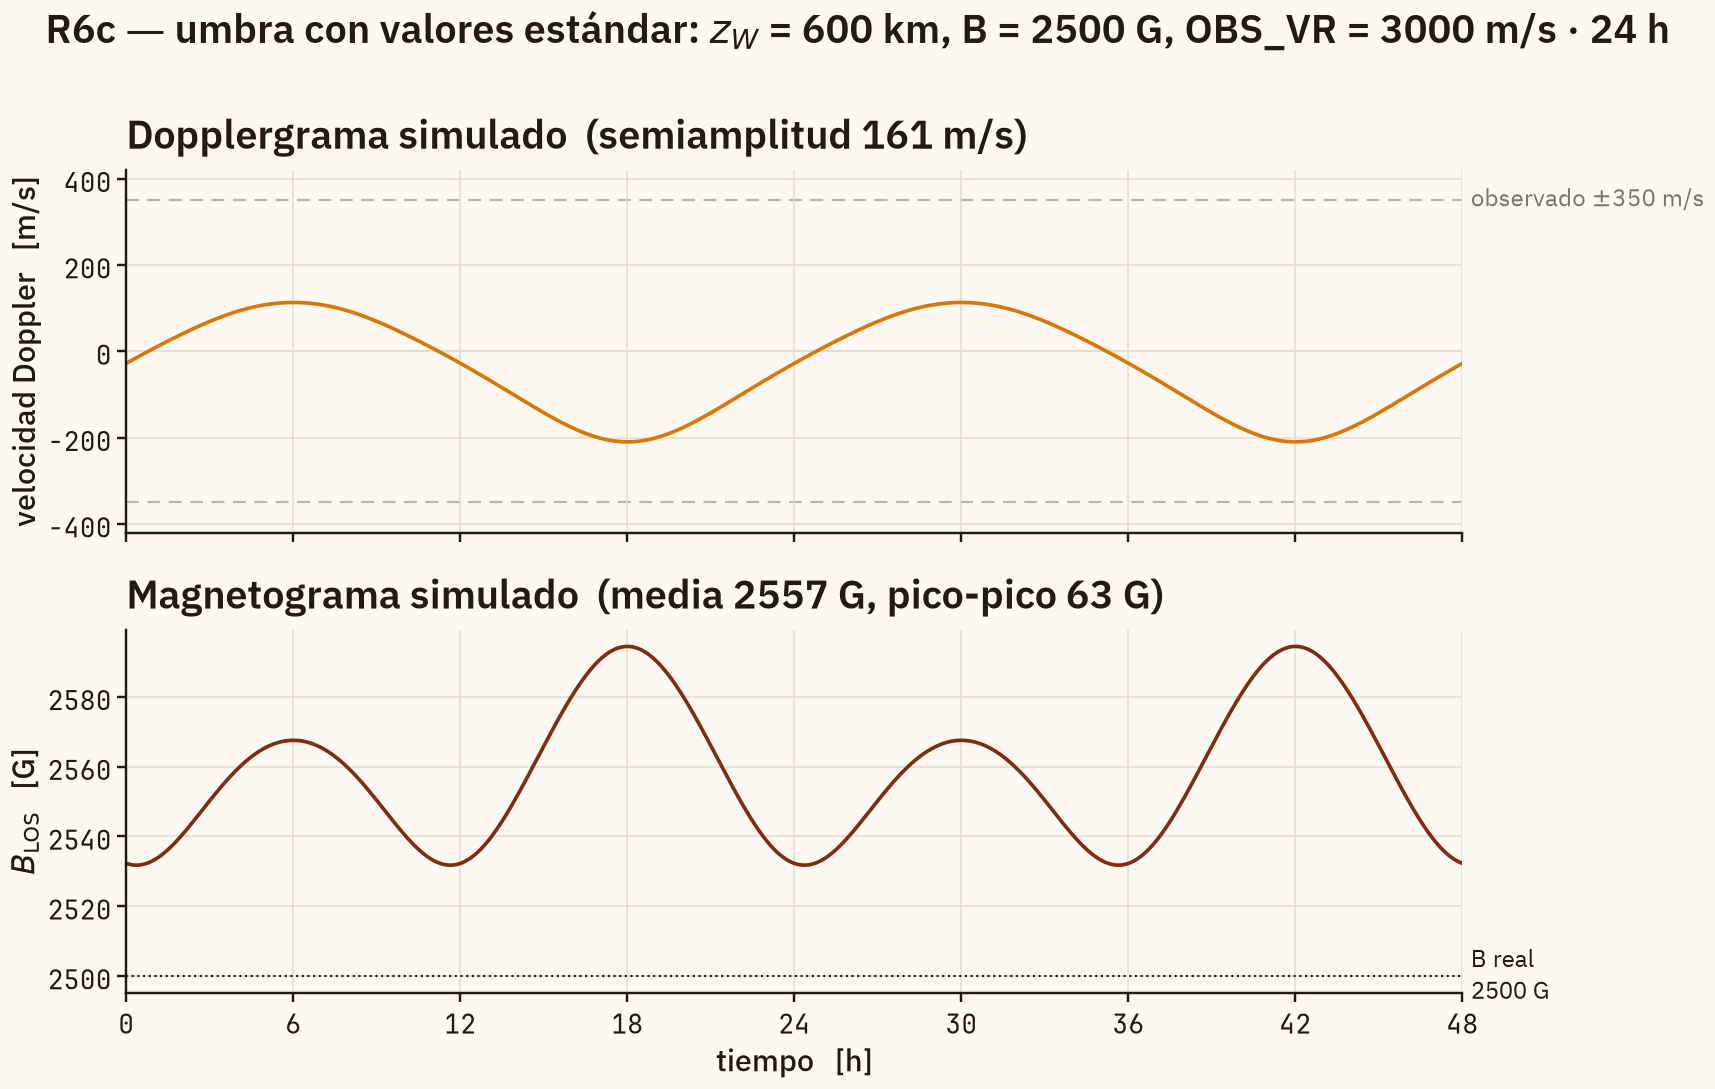

Dopplergrama : semiamplitud  161.5 m/s   media   -37.1 m/s
Magnetograma : semiamplitud   31.3 G     media  2557.4 G   (B real 2500 G)


In [16]:
o_std = C_est['pipeline']        # z_W = Z_W_REF, B = B_GAUSS, OBS_VR = A_ORB sin(2 pi t / 24 h)
dop = o_std['artifact_rel']
mag = o_std['B_los']

fig, axes = plt.subplots(2, 1, figsize=FIGSIZE_STACK, sharex=True)

ax = axes[0]
for v in (-cfg.V_OBSERVED_RESIDUAL, cfg.V_OBSERVED_RESIDUAL):
    ax.axhline(v, color='#b9b5a7', lw=1.4, ls=(0, (6, 4)), zorder=0)
ax.annotate(f'observado $\\pm${cfg.V_OBSERVED_RESIDUAL:.0f} m/s',
            xy=(48.3, cfg.V_OBSERVED_RESIDUAL), fontsize=FS_ANNOT + 2,
            color='#7a7568', va='center', annotation_clip=False)
ax.axhline(0, color=C_GRID, lw=1.2)
ax.plot(t, dop, color=C_ACCENT, lw=LW_SERIES)
lim = 1.2 * max(cfg.V_OBSERVED_RESIDUAL, np.abs(dop).max())
ax.set_ylim(-lim, lim)
ax.set_ylabel('velocidad Doppler   [m/s]')
ax.set_title(f'Dopplergrama simulado  (semiamplitud {amp(dop):.0f} m/s)', loc='left')
mono_ticks(ax)

ax = axes[1]
ax.axhline(cfg.B_GAUSS, color=C_INK, lw=1.4, ls=':')
ax.annotate(f'B real\n{cfg.B_GAUSS:.0f} G', xy=(48.3, cfg.B_GAUSS), fontsize=FS_ANNOT + 2,
            color=C_INK, va='center', annotation_clip=False)
ax.plot(t, mag, color=C_SERIES_3, lw=LW_SERIES)
ax.set_xlabel('tiempo   [h]')
ax.set_ylabel('$B_{\\rm LOS}$   [G]')
ax.set_title(f'Magnetograma simulado  (media {mag.mean():.0f} G, '
             f'pico-pico {np.ptp(mag):.0f} G)', loc='left')
ax.set_xlim(0, 48)
ax.set_xticks(np.arange(0, 49, 6))
mono_ticks(ax)

fig.suptitle(f'R6c — umbra con valores estándar: $z_W$ = {cfg.Z_W_REF:.0f} km, '
             f'B = {cfg.B_GAUSS:.0f} G, OBS_VR = {cfg.A_ORB:.0f} m/s · 24 h',
             fontsize=FS_TITLE, y=1.0)
fig.tight_layout()
save_fig(fig, 'R6c_dopplergrama_magnetograma')
plt.show()

print(f'Dopplergrama : semiamplitud {amp(dop):6.1f} m/s   media {dop.mean():+7.1f} m/s')
print(f'Magnetograma : semiamplitud {amp(mag):6.1f} G     media {mag.mean():7.1f} G'
      f'   (B real {cfg.B_GAUSS:.0f} G)')

### R7 — Espectro: el dopplerograma en los armónicos impares, $B_{\rm LOS}$ en los pares

El artefacto y la contaminación del magnetograma son dos respuestas periódicas a
un único forzamiento sinusoidal, así que sus espectros son espectros de líneas:
armónicos de la frecuencia orbital. La paridad separa a los dos.

saved → ../figures/R7_espectro.png


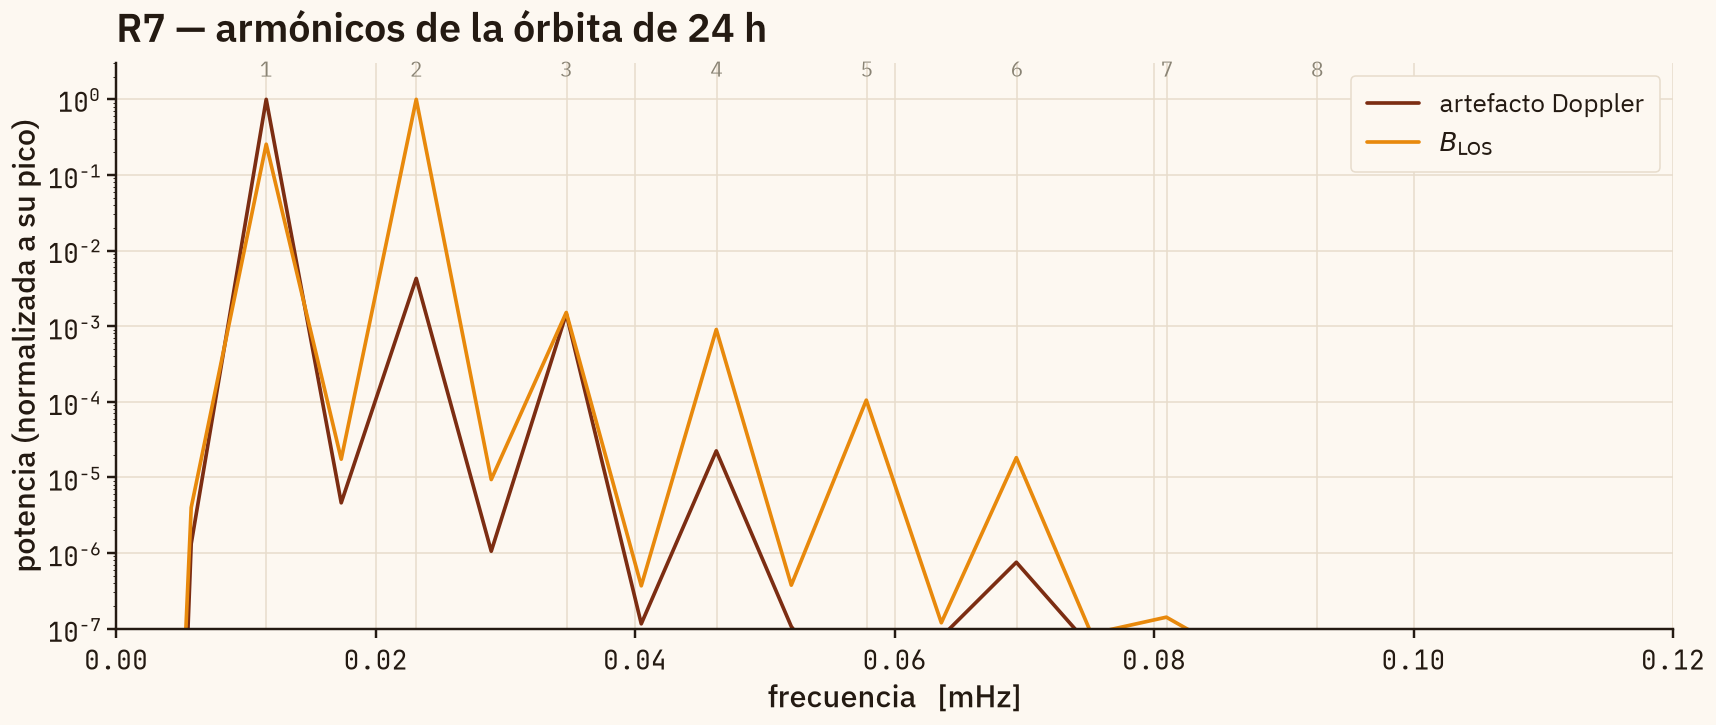

artefacto: picos mas altos (armonico de 24 h, potencia relativa)
   n =  1.00   1.000e+00
   n =  2.00   4.279e-03
   n =  3.00   1.457e-03
   n =  4.00   2.237e-05
   n =  1.50   4.601e-06
B_LOS: picos mas altos (armonico de 24 h, potencia relativa)
   n =  2.00   1.000e+00
   n =  1.00   2.550e-01
   n =  3.00   1.516e-03
   n =  4.00   9.030e-04
   n =  5.00   1.050e-04


In [17]:
XLIM = (0, 0.12)   # mHz
N_PEAKS = 5
cad = (t[1] - t[0]) * 3600.0

def psd(y):
    y = np.asarray(y, float) - np.mean(y)
    n = y.size
    fsr = 1.0 / cad
    pw = 2.0 * np.abs(np.fft.rfft(y)) ** 2 / (fsr * n)
    return np.fft.rfftfreq(n, d=cad) * 1e3, pw

o = C_est['pipeline']
f1, p1 = psd(o['artifact_rel'])
f2, p2 = psd(o['B_los'])
f_orb = 1e3 / (cfg.P_ORB_HOURS * 3600.0)

fig, ax = plt.subplots(figsize=(16, 7))
ax.semilogy(f1, p1 / p1[1:].max(), color=C_SERIES_3, lw=LW_SERIES,
            label='artefacto Doppler')
ax.semilogy(f2, p2 / p2[1:].max(), color=C_SERIES_1, lw=LW_SERIES,
            label='$B_{\\rm LOS}$')
for k in range(1, 9):
    ax.axvline(k * f_orb, color=C_GRID, lw=1.0, zorder=0)
    if k * f_orb < XLIM[1]:
        ax.annotate(f'{k}', xy=(k * f_orb, 2.0), ha='center',
                    fontsize=FS_ANNOT, color='#8a8475', annotation_clip=False)
ax.set_xlim(*XLIM); ax.set_ylim(1e-7, 3)
ax.set_xlabel('frecuencia   [mHz]')
ax.set_ylabel('potencia (normalizada a su pico)')
ax.set_title('R7 — armónicos de la órbita de 24 h', loc='left')
ax.legend(loc='upper right', fontsize=FS_ANNOT + 3)
mono_ticks(ax)
fig.tight_layout()
save_fig(fig, 'R7_espectro')
plt.show()

for nombre, f_, p_ in (('artefacto', f1, p1), ('B_LOS', f2, p2)):
    m = (f_ > 0) & (f_ < XLIM[1])
    idx = np.argsort(p_[m])[::-1][:N_PEAKS]
    print(f'{nombre}: picos mas altos (armonico de 24 h, potencia relativa)')
    for i in idx:
        print(f'   n = {f_[m][i]/f_orb:5.2f}   {p_[m][i]/p_[m].max():.3e}')

## §8 — La corrección del efecto Zeeman: ¿cancela la media LCP/RCP?

El pipeline no corrige el Zeeman con un modelo: lo cancela por simetría. Mide la
velocidad de cada polarización circular por separado y promedia,

$$V = \tfrac12\,(v_{\rm LCP} + v_{\rm RCP}),\qquad
B_{\rm LOS} = (v_{\rm LCP} - v_{\rm RCP})\cdot K_m$$

Si el perfil es simétrico, LCP ve la línea en $+\Delta\lambda_B$, RCP en
$-\Delta\lambda_B$, y los dos corrimientos se van en la suma. La pregunta de
esta sección es si eso sigue valiendo con los filtros reales.

A 2500 G el desdoblamiento es grande: $\Delta\lambda_B = 4.67\times10^{-13}\,g\,
\lambda_0^2 B$ con $g = 2.5$ da **111 mÅ**, o 5.4 km/s de velocidad
equivalente, más que el ancho de un filtro.

In [18]:
dlB = zeeman_shift(cfg.B_GAUSS)
print(f'Delta lambda_B a {cfg.B_GAUSS:.0f} G = {1e3*abs(dlB):.1f} mA'
      f'  =  {cfg.DVDL*abs(dlB):.0f} m/s equivalentes')
print(f'FWHM de un filtro = {fs.fwhm().mean():.0f} mA\n')

Bs = np.linspace(0.0, 3000.0, 31)
Z = {}
for etiqueta, (zW, ov) in {
        'linea en reposo ($z_W$=0, OBS_VR=0)': (0.0, 0.0),
        'solo orbita ($z_W$=0, OBS_VR=3000)': (0.0, 3000.0),
        'solo Wilson ($z_W$=600, OBS_VR=0)': (600.0, 0.0),
        'Wilson + orbita ($z_W$=600, OBS_VR=3000)': (600.0, 3000.0)}.items():
    Z[etiqueta] = np.array([P.observables(zW, b, 0.0, ov)['artifact_rel'][0] for b in Bs])

print('artefacto relativo [m/s] frente a B, por configuracion')
print(f'{"B [G]":>7}' + ''.join(f'{e.split(" (")[0][:16]:>18}' for e in Z))
for b in (0, 1000, 2000, 2500, 3000):
    i = int(np.argmin(np.abs(Bs - b)))
    print(f'{Bs[i]:7.0f}' + ''.join(f'{Z[e][i]:18.1f}' for e in Z))

print('\nEl mismo barrido con el estimador delta (instrumento ideal):')
d_rest = np.array([P.observables(0.0, b, 0.0, 0.0, estimator='delta')['artifact_rel'][0] for b in Bs])
d_full = np.array([P.observables(600.0, b, 0.0, 3000.0, estimator='delta')['artifact_rel'][0] for b in Bs])
print(f'  linea en reposo : |artefacto| max = {np.abs(d_rest).max():.3f} m/s')
print(f'  Wilson + orbita : |artefacto| max = {np.abs(d_full).max():.1f} m/s')

Delta lambda_B a 2500 G = 111.2 mA  =  5402 m/s equivalentes
FWHM de un filtro = 76 mA

artefacto relativo [m/s] frente a B, por configuracion
  B [G]   linea en reposo       solo orbita       solo Wilson   Wilson + orbita
      0               0.0               0.0             -17.1              -4.0
   1000               0.6              -0.6             -18.3               8.1
   2000               0.3              -0.2             -21.2              67.2
   2500               0.1               0.6             -27.5             113.3
   3000               0.2               1.6             -37.7             154.5

El mismo barrido con el estimador delta (instrumento ideal):


  linea en reposo : |artefacto| max = 0.001 m/s


  Wilson + orbita : |artefacto| max = 263.8 m/s


saved → ../figures/R8_zeeman_cancelacion.png


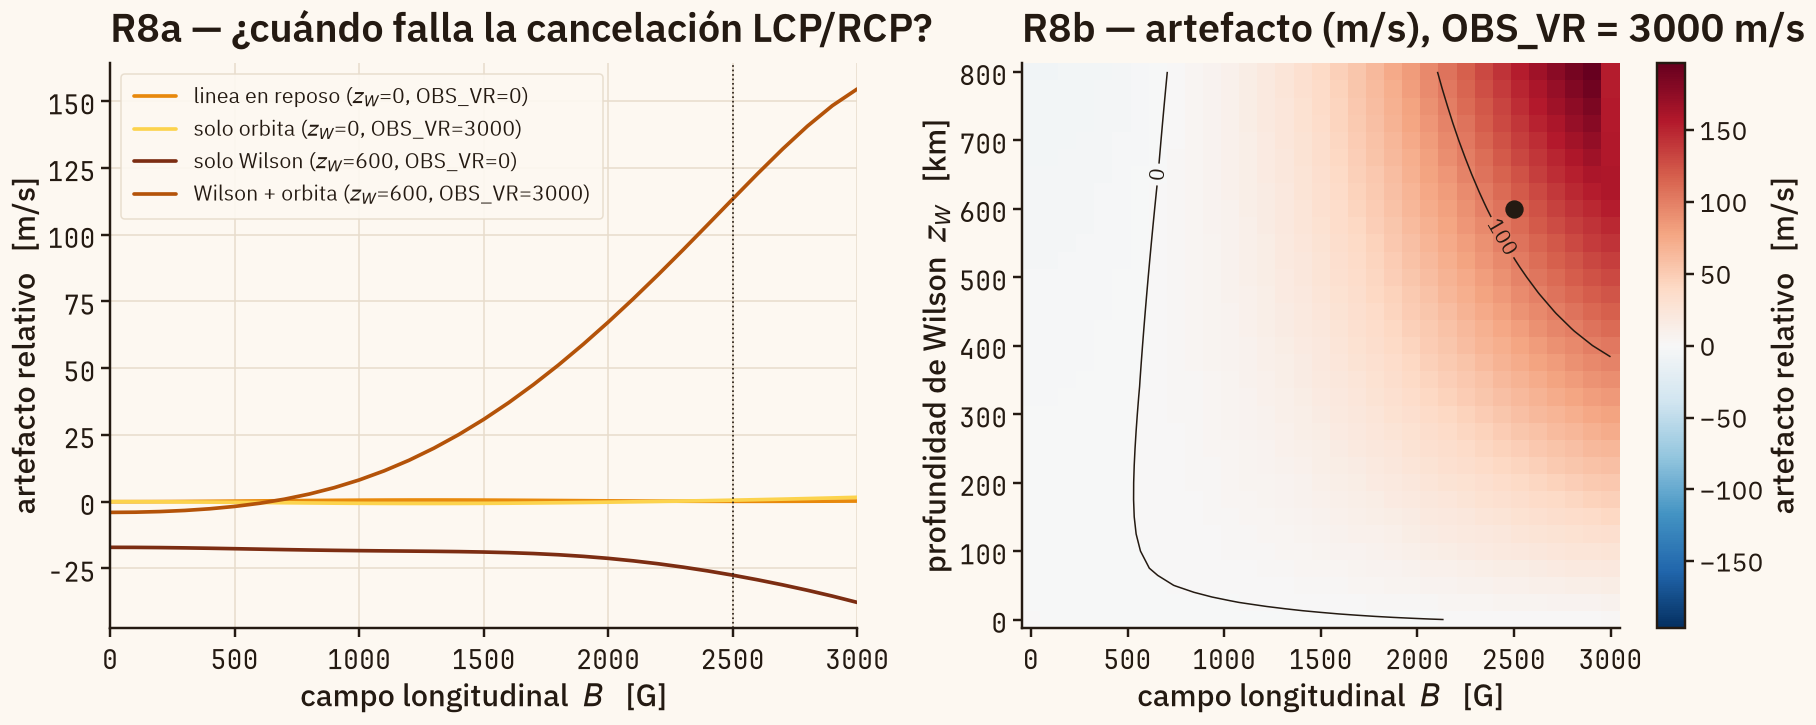

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

ax = axes[0]
ax.axhline(0, color=C_GRID, lw=1.2)
for k, (etiqueta, cur) in enumerate(Z.items()):
    ax.plot(Bs, cur, lw=LW_SERIES, color=PALETTE[k % 4], label=etiqueta)
ax.axvline(cfg.B_GAUSS, color=C_INK, lw=1.1, ls=':')
ax.set_xlabel('campo longitudinal  $B$   [G]')
ax.set_ylabel('artefacto relativo   [m/s]')
ax.set_xlim(0, 3000)
ax.set_title('R8a — ¿cuándo falla la cancelación LCP/RCP?', loc='left')
ax.legend(loc='upper left', fontsize=FS_ANNOT, framealpha=0.92)
mono_ticks(ax)

ax = axes[1]
zz_grid = np.linspace(0, 800, 33)
bb_grid = np.linspace(0, 3000, 33)
M = np.array([[P.observables(zi, bi, 0.0, 3000.0)['artifact_rel'][0]
               for bi in bb_grid] for zi in zz_grid])
vmax = np.abs(M).max()
im = ax.pcolormesh(bb_grid, zz_grid, M, cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                   shading='nearest')
cs = ax.contour(bb_grid, zz_grid, M, levels=[-200, -100, 0, 100, 200],
                colors=C_INK, linewidths=1.0)
ax.clabel(cs, fmt='%.0f', fontsize=FS_ANNOT)
ax.plot([cfg.B_GAUSS], [cfg.Z_W_REF], marker='o', ms=11, color=C_INK)
ax.set_xlabel('campo longitudinal  $B$   [G]')
ax.set_ylabel('profundidad de Wilson  $z_W$   [km]')
ax.set_title('R8b — artefacto (m/s), OBS_VR = 3000 m/s', loc='left')
ax.grid(False)
fig.colorbar(im, ax=ax, label='artefacto relativo   [m/s]')
mono_ticks(ax)

fig.tight_layout()
save_fig(fig, 'R8_zeeman_cancelacion')
plt.show()

### R9 — Por qué falla: los perfiles que ve cada polarización

Con la línea simétrica y en reposo, los seis filtros muestrean LCP y RCP de
forma espejada y la media cancela el corrimiento. En cuanto la órbita corre la
línea *y* la umbra la deforma, cada polarización cae sobre una parte distinta de
la rejilla de filtros, los dos errores dejan de ser opuestos, y el residual
sobrevive al promedio.

saved → ../figures/R9_perfiles_lcp_rcp.png


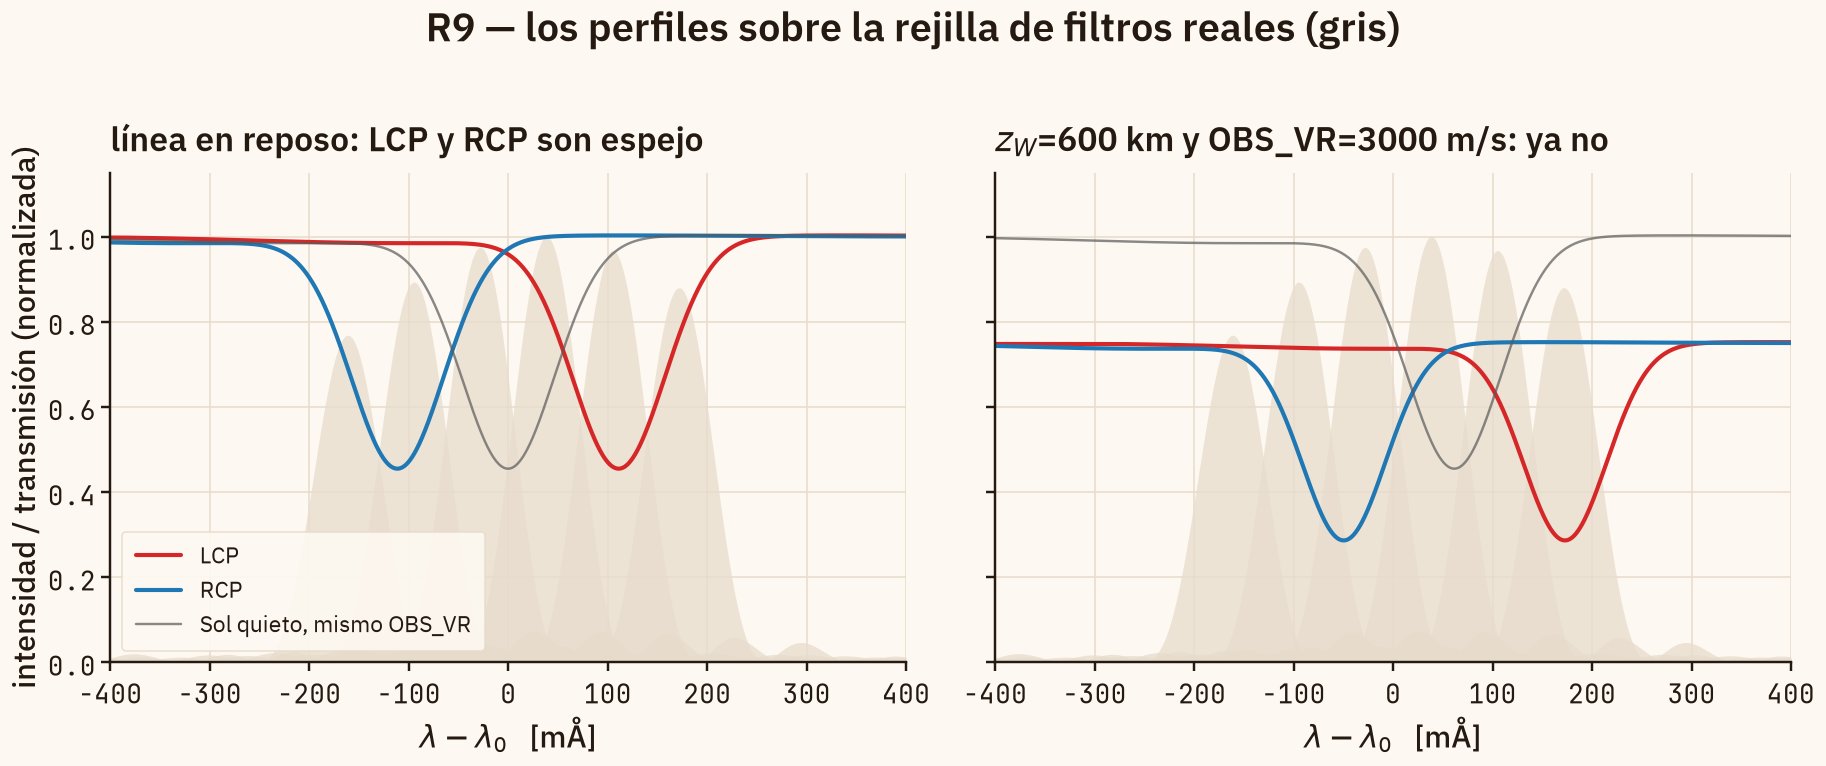

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)
lamp = np.linspace(-0.40, 0.40, 1500)
cal = EPOCAS[FSN_REF]['cal']

for ax, (zW, ov, titulo) in zip(axes, [
        (0.0, 0.0, 'línea en reposo: LCP y RCP son espejo'),
        (cfg.Z_W_REF, 3000.0, f'$z_W$={cfg.Z_W_REF:.0f} km y OBS_VR=3000 m/s: ya no')]):
    for j in range(6):
        ax.fill_between(1e3 * fs.lam[np.abs(fs.lam) <= 0.40],
                        0, fs.T[j][np.abs(fs.lam) <= 0.40] / fs.T.max(),
                        color=C_GRID, alpha=0.75, lw=0, zorder=0)
    shift = ov * jd.parse_hmiparam()['dlamdv']
    for pol, col in (('LCP', 'tab:red'), ('RCP', 'tab:blue')):
        L = umbral_line(zW, cfg.B_GAUSS, pol, mu=P.mu, calibration=cal)
        ax.plot(1e3 * lamp, L(lamp - shift), color=col, lw=LW_SERIES + 0.3, label=pol)
    Lq = umbral_line(0.0, 0.0, 'I', mu=P.mu, calibration=cal)
    ax.plot(1e3 * lamp, Lq(lamp - shift), color='0.35', lw=1.6, alpha=0.7,
            label='Sol quieto, mismo OBS_VR')
    ax.set_xlabel(r'$\lambda - \lambda_0$   [mÅ]')
    ax.set_xlim(-400, 400); ax.set_ylim(0, 1.15)
    ax.set_title(titulo, loc='left', fontsize=FS_LABEL + 2)
    mono_ticks(ax)
axes[0].set_ylabel('intensidad / transmisión (normalizada)')
axes[0].legend(loc='lower left', fontsize=FS_ANNOT + 1, framealpha=0.92)
fig.suptitle('R9 — los perfiles sobre la rejilla de filtros reales (gris)',
             fontsize=FS_TITLE, y=1.01)
fig.tight_layout()
save_fig(fig, 'R9_perfiles_lcp_rcp')
plt.show()

## §9 — Apartado: el perfil Zeeman completo (triplete σ±, π)

Hasta aquí el Zeeman se trató como un corrimiento rígido de toda la línea, que
es la aproximación de la versión sintética. Fe I 6173 es en realidad un
**triplete Zeeman normal** ($J=1\to J=0$, $g_{\rm eff}=2.5$): se parte en tres
componentes, y con el campo inclinado un ángulo $\gamma$ respecto a la línea de
visión los perfiles de absorción de Stokes son

$$\varphi_I = \tfrac12\varphi_\pi\sin^2\gamma
+ \tfrac14(\varphi_b + \varphi_r)(1+\cos^2\gamma),\qquad
\varphi_V = \tfrac12(\varphi_r - \varphi_b)\cos\gamma$$

y HMI mide $I \pm V$. Dos límites sirven de test:

- $\gamma = 0$: LCP $= \varphi_r$ y RCP $= \varphi_b$, **exactamente** el
  corrimiento rígido $\pm\Delta\lambda_B$.
- $\gamma = 90^\circ$: $\varphi_V = 0$, LCP $=$ RCP y el magnetograma da cero.

La diferencia importante es la **componente π**, que se queda en el centro de la
línea y aparece con el mismo peso en las dos polarizaciones. Eso no se cancela
en la media y es lo que rompe la corrección.

### Pseudocódigo de `zeeman.triplet_line`

```
component_weights(gamma):
    w_pi    = sin^2(gamma)/2
    w_sigma = (1 + cos^2(gamma))/4
    w_V     = cos(gamma)/2
    # w_pi + 2*w_sigma = 1 exactamente: la anchura equivalente se conserva

triplet_line(z_W, B, gamma, pol):
    f_c, f_d, f_s = factores de Wilson
    d_lam_B       = 4.67e-13 * g * lam0^2 * B
    phi_pi(lam) = D(lam / f_s)
    phi_b (lam) = D((lam + d_lam_B) / f_s)
    phi_r (lam) = D((lam - d_lam_B) / f_s)
    phi_I = w_pi*phi_pi + w_sigma*(phi_b + phi_r)
    phi_V = w_V*(phi_r - phi_b)
    return Ic*f_c - f_d*(phi_I  +-  phi_V)        # + para LCP, - para RCP
```

**Limitación honesta:** esto es superposición de componentes sobre un perfil de
absorción dado, no una síntesis Milne-Eddington. No incluye la saturación de la
línea ni el acoplamiento de la función fuente con el campo, que a 2500 G ya
importan. Es, eso sí, estrictamente mejor que el corrimiento rígido.

In [21]:
x = np.linspace(-0.5, 0.5, 801)
print('Tests del triplete:')
for pol in ('LCP', 'RCP'):
    a = zz.triplet_line(600, 2500, 0.0, pol, mu=P.mu, calibration=cal)(x)
    b = umbral_line(600, 2500, pol, mu=P.mu, calibration=cal)(x)
    print(f'  gamma=0, {pol}: identico al corrimiento rigido -> '
          f'{np.allclose(a, b)}  (max dif {np.abs(a-b).max():.2e})')
l90 = zz.triplet_line(600, 2500, 90.0, 'LCP', mu=P.mu, calibration=cal)(x)
r90 = zz.triplet_line(600, 2500, 90.0, 'RCP', mu=P.mu, calibration=cal)(x)
print(f'  gamma=90: LCP == RCP -> {np.allclose(l90, r90)}')
o0 = P.observables(600, 0.0, 0.0, 3000.0, zeeman='triplet', gamma_deg=45)
print(f'  B=0 con cualquier gamma: B_LOS = {o0["B_los"][0]:.3e} G')
print('\n  pesos de las componentes:')
for g in (0, 15, 30, 45, 60, 75, 90):
    wp, ws, wv = zz.component_weights(g)
    print(f'    gamma={g:3d}: w_pi={wp:.4f}  w_sigma={ws:.4f}  suma={wp+2*ws:.6f}  w_V={wv:+.4f}')

Tests del triplete:
  gamma=0, LCP: identico al corrimiento rigido -> True  (max dif 0.00e+00)
  gamma=0, RCP: identico al corrimiento rigido -> True  (max dif 0.00e+00)
  gamma=90: LCP == RCP -> True
  B=0 con cualquier gamma: B_LOS = 0.000e+00 G

  pesos de las componentes:
    gamma=  0: w_pi=0.0000  w_sigma=0.5000  suma=1.000000  w_V=+0.5000
    gamma= 15: w_pi=0.0335  w_sigma=0.4833  suma=1.000000  w_V=+0.4830
    gamma= 30: w_pi=0.1250  w_sigma=0.4375  suma=1.000000  w_V=+0.4330
    gamma= 45: w_pi=0.2500  w_sigma=0.3750  suma=1.000000  w_V=+0.3536
    gamma= 60: w_pi=0.3750  w_sigma=0.3125  suma=1.000000  w_V=+0.2500
    gamma= 75: w_pi=0.4665  w_sigma=0.2667  suma=1.000000  w_V=+0.1294
    gamma= 90: w_pi=0.5000  w_sigma=0.2500  suma=1.000000  w_V=+0.0000


In [22]:
gammas = np.linspace(0.0, 90.0, 31)
G_art = np.array([P.observables(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, 3000.0,
                                zeeman='triplet', gamma_deg=g)['artifact_rel'][0]
                  for g in gammas])
G_blos = np.array([P.observables(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, 3000.0,
                                 zeeman='triplet', gamma_deg=g)['B_los'][0]
                   for g in gammas])
rigido = P.observables(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, 3000.0)['artifact_rel'][0]

GAMMAS_C = [0.0, 30.0, 45.0, 60.0]
G_t = {g: P.observables(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, obs,
                        zeeman='triplet', gamma_deg=g) for g in GAMMAS_C}

print(f'z_W = {cfg.Z_W_REF:.0f} km, B = {cfg.B_GAUSS:.0f} G\n')
print(f'{"gamma":>6} {"artefacto @3km/s":>18} {"B_LOS [G]":>11} {"semiamplitud 24h":>18}')
for g in GAMMAS_C:
    i = int(np.argmin(np.abs(gammas - g)))
    print(f'{g:6.0f} {G_art[i]:18.1f} {G_blos[i]:11.1f} {amp(G_t[g]["artifact_rel"]):18.1f}')
print(f'\ncorrimiento rigido (equivale a gamma=0): {rigido:+.1f} m/s, '
      f'semiamplitud {amp(C_est["pipeline"]["artifact_rel"]):.1f} m/s')
print(f'residual observado: +-{cfg.V_OBSERVED_RESIDUAL:.0f} m/s')
amps = np.array([amp(G_t[g]['artifact_rel']) for g in GAMMAS_C])
i_obs = int(np.argmin(np.abs(amps - cfg.V_OBSERVED_RESIDUAL)))
print(f'la amplitud observada se alcanza alrededor de gamma ~ {GAMMAS_C[i_obs]:.0f} grados')

z_W = 600 km, B = 2500 G

 gamma   artefacto @3km/s   B_LOS [G]   semiamplitud 24h
     0              113.3      2567.5              161.5
    30             -169.8      2218.2              197.6
    45             -346.3      1831.0              405.7
    60             -410.9      1321.8              479.1

corrimiento rigido (equivale a gamma=0): +113.3 m/s, semiamplitud 161.5 m/s
residual observado: +-350 m/s
la amplitud observada se alcanza alrededor de gamma ~ 45 grados


saved → ../figures/R10_triplete_zeeman.png


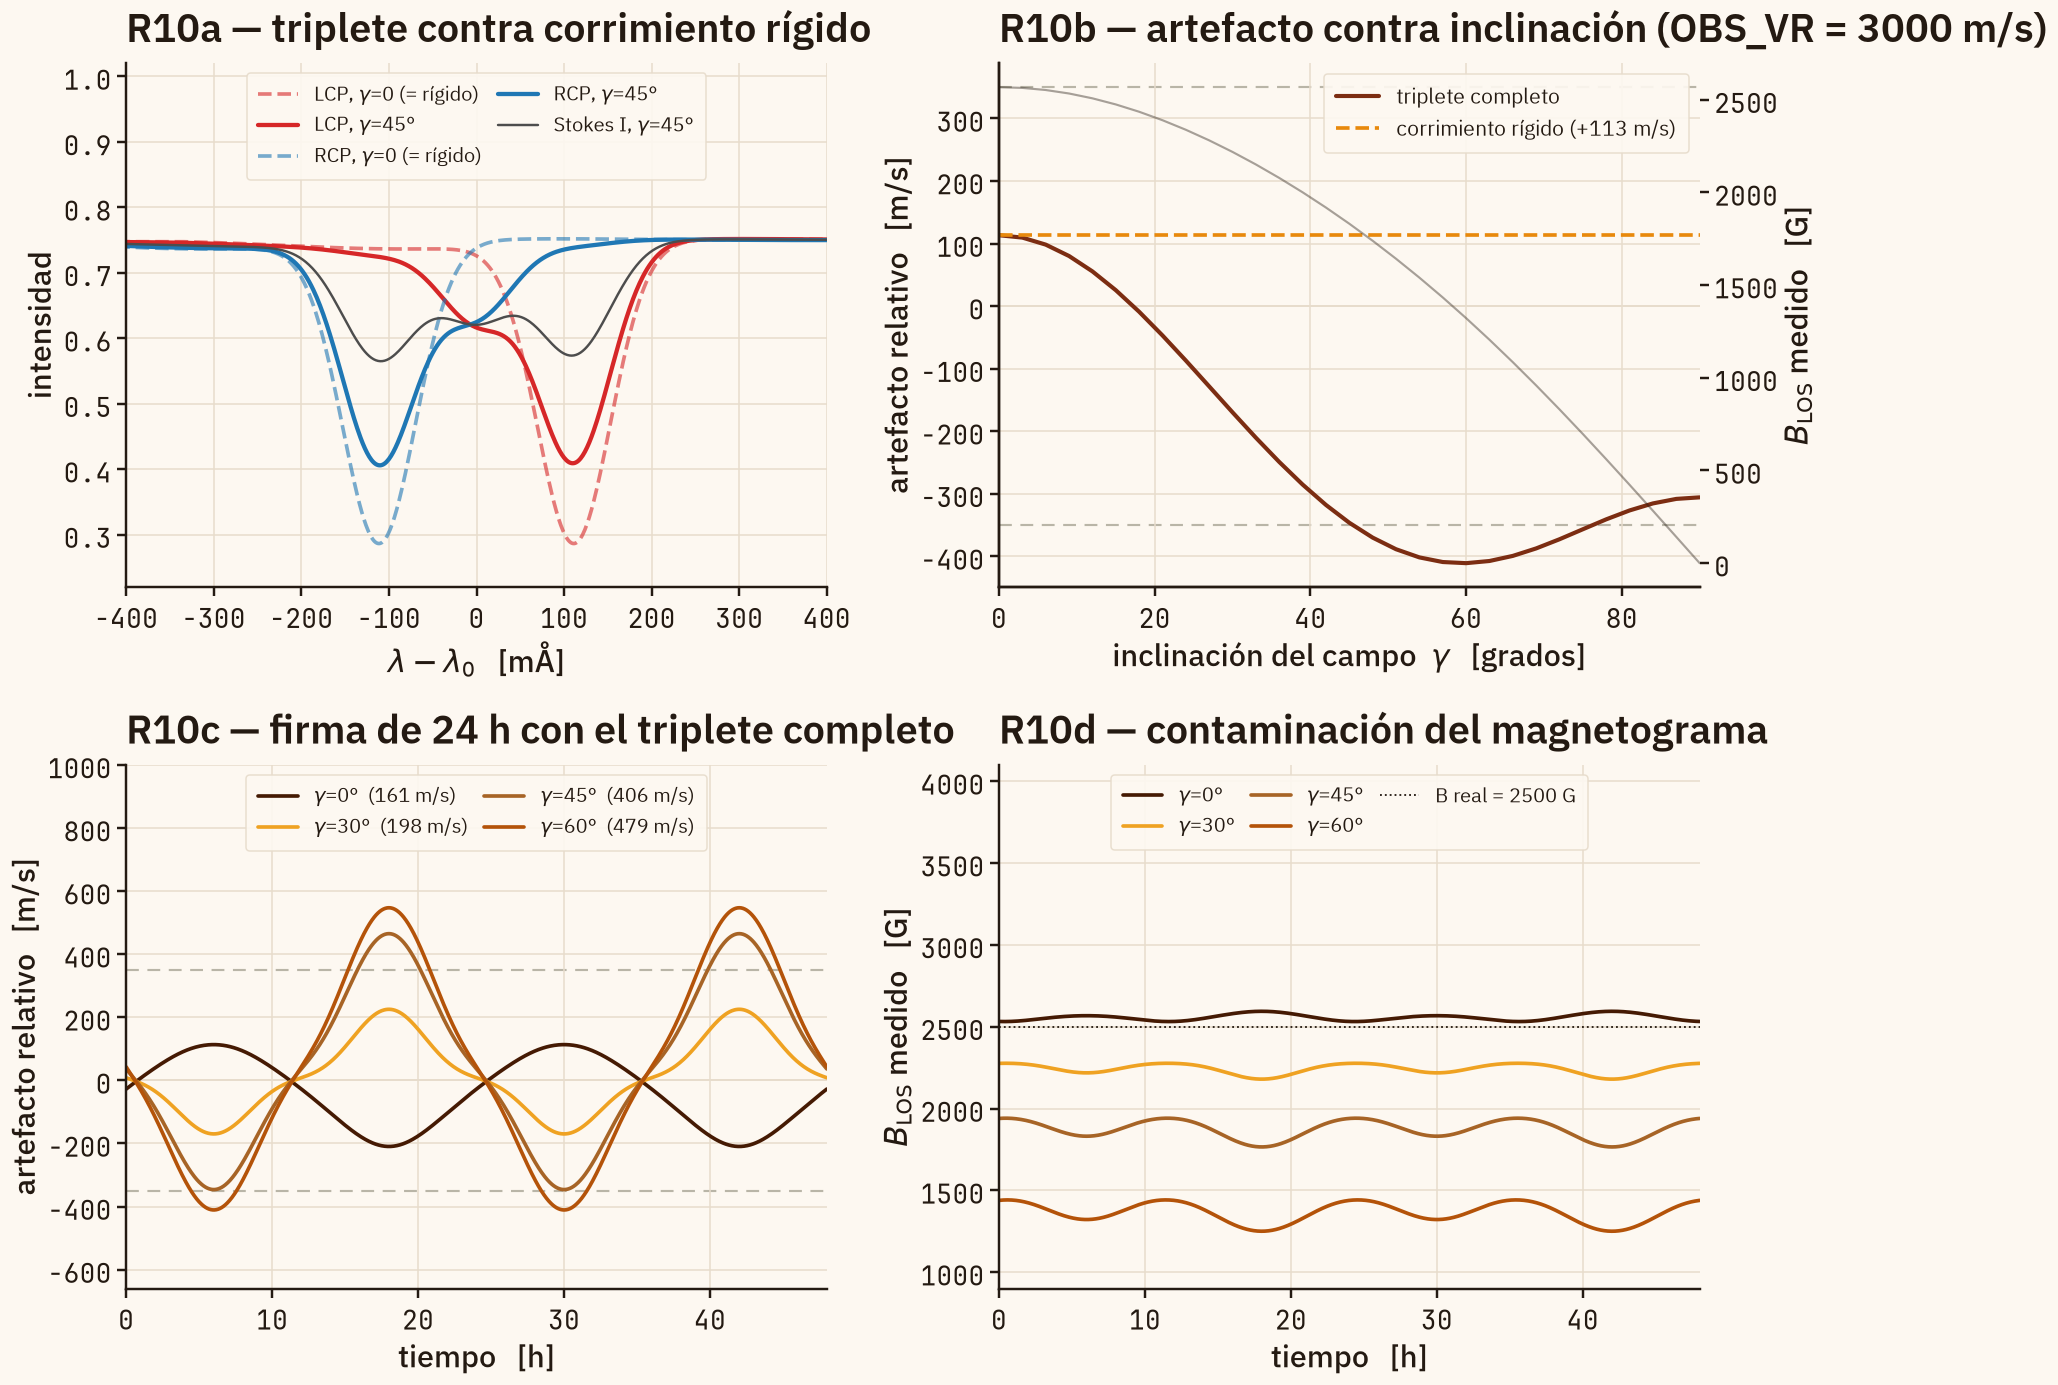

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(17, 13))

ax = axes[0, 0]
for pol, col in (('LCP', 'tab:red'), ('RCP', 'tab:blue')):
    ax.plot(1e3 * x, zz.triplet_line(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, pol,
            mu=P.mu, calibration=cal)(x), color=col, lw=LW_SERIES, ls='--', alpha=0.6,
            label=f'{pol}, $\\gamma$=0 (= rígido)')
    ax.plot(1e3 * x, zz.triplet_line(cfg.Z_W_REF, cfg.B_GAUSS, 45.0, pol,
            mu=P.mu, calibration=cal)(x), color=col, lw=LW_SERIES + 0.4,
            label=f'{pol}, $\\gamma$=45°')
ax.plot(1e3 * x, zz.triplet_line(cfg.Z_W_REF, cfg.B_GAUSS, 45.0, 'I',
        mu=P.mu, calibration=cal)(x), color='0.3', lw=1.6, label='Stokes I, $\\gamma$=45°')
ax.set_xlabel(r'$\lambda - \lambda_0$   [mÅ]')
ax.set_ylabel('intensidad')
ax.set_xlim(-400, 400); ax.set_ylim(0.22, 1.02)
ax.set_title('R10a — triplete contra corrimiento rígido', loc='left')
ax.legend(loc='upper center', fontsize=FS_ANNOT - 1, framealpha=0.92, ncols=2,
          columnspacing=0.8)
mono_ticks(ax)

ax = axes[0, 1]
ax.axhline(0, color=C_GRID, lw=1.2)
ax.plot(gammas, G_art, color=C_SERIES_3, lw=LW_SERIES + 0.3, label='triplete completo')
ax.axhline(rigido, color=C_SERIES_1, lw=LW_SERIES, ls='--',
           label=f'corrimiento rígido ({rigido:+.0f} m/s)')
for v in (-cfg.V_OBSERVED_RESIDUAL, cfg.V_OBSERVED_RESIDUAL):
    ax.axhline(v, color='#b9b5a7', lw=1.4, ls=(0, (6, 4)), zorder=0)
ax.set_xlabel('inclinación del campo  $\\gamma$   [grados]')
ax.set_ylabel('artefacto relativo   [m/s]')
ax.set_xlim(0, 90)
ax.set_title('R10b — artefacto contra inclinación (OBS_VR = 3000 m/s)', loc='left')
ax.legend(loc='upper right', fontsize=FS_ANNOT, framealpha=0.92)
axb = ax.twinx()
axb.plot(gammas, G_blos, color=C_INK, lw=1.4, alpha=0.4)
axb.set_ylabel('$B_{\\rm LOS}$ medido   [G]', color=C_INK)
axb.grid(False)
mono_ticks(ax, axb)

ax = axes[1, 0]
for v in (-cfg.V_OBSERVED_RESIDUAL, cfg.V_OBSERVED_RESIDUAL):
    ax.axhline(v, color='#b9b5a7', lw=1.4, ls=(0, (6, 4)), zorder=0)
ax.axhline(0, color=C_GRID, lw=1.2)
for k, g in enumerate(GAMMAS_C):
    ax.plot(t, G_t[g]['artifact_rel'], lw=LW_SERIES,
            color=CMAP_AMBER(k / (len(GAMMAS_C) - 1)),
            label=f'$\\gamma$={g:.0f}°  ({amp(G_t[g]["artifact_rel"]):.0f} m/s)')
ax.set_xlabel('tiempo   [h]')
ax.set_ylabel('artefacto relativo   [m/s]')
ax.set_xlim(0, 48)
ax.set_ylim(-660, 1000)
ax.set_title('R10c — firma de 24 h con el triplete completo', loc='left')
ax.legend(loc='upper center', ncols=2, fontsize=FS_ANNOT - 1, columnspacing=0.8,
          framealpha=0.92)
mono_ticks(ax)

ax = axes[1, 1]
ax.axhline(0, color=C_GRID, lw=1.2)
for k, g in enumerate(GAMMAS_C):
    ax.plot(t, G_t[g]['B_los'], lw=LW_SERIES,
            color=CMAP_AMBER(k / (len(GAMMAS_C) - 1)), label=f'$\\gamma$={g:.0f}°')
ax.axhline(cfg.B_GAUSS, color=C_INK, lw=1.2, ls=':', label=f'B real = {cfg.B_GAUSS:.0f} G')
ax.set_xlabel('tiempo   [h]')
ax.set_ylabel('$B_{\\rm LOS}$ medido   [G]')
ax.set_xlim(0, 48); ax.set_ylim(900, 4100)
ax.set_title('R10d — contaminación del magnetograma', loc='left')
ax.legend(loc='upper center', ncols=3, fontsize=FS_ANNOT - 1, columnspacing=0.8,
          framealpha=0.92)
mono_ticks(ax)

fig.tight_layout()
save_fig(fig, 'R10_triplete_zeeman')
plt.show()

## §10 — Resumen

In [24]:
# el mismo Exp. C con la version sintetica, para que la comparacion sea completa
from hmi_artifact_sim.pipeline import LookupTable
from hmi_artifact_sim.artifact import measure_artifact
lut_s = LookupTable(v_min=cfg.LUT_V_MIN_EXT, v_max=cfg.LUT_V_MAX_EXT, n=cfg.LUT_N_EXT)
art_s = measure_artifact(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, obs, lookup=lut_s)[0]
art_s_q = measure_artifact(0.0, 0.0, 0.0, obs, lookup=lut_s)[0]
sint_semi = f'{amp(art_s - art_s_q):.0f} m/s'
sint_zee = measure_artifact(0.0, cfg.B_GAUSS, 0.0, 0.0, lookup=lut_s)[0]
iB = int(np.argmin(np.abs(Bs - cfg.B_GAUSS)))

filas = [
    ('reproduccion de la LUT real (rms, pixel central)', '-',
     f'{np.sqrt(np.mean((VAL[FSN_REF]["centro"]["mia"]-VAL[FSN_REF]["centro"]["real"])**2)):.1f} m/s'),
    ('Exp. A: |artefacto| maximo', '< 1 m/s',
     f'{max(np.abs(o["artifact"]).max() for o in A.values()):.1f} m/s'),
    ('Exp. B: pendiente a OBS_VR=3000', '-', f'{pend:.3f} (m/s)/km'),
    ('solo Zeeman (z_W=0, B=2500, linea en reposo)', f'{float(np.atleast_1d(sint_zee)[0]):+.1f} m/s',
     f'{Z["linea en reposo ($z_W$=0, OBS_VR=0)"][iB]:+.1f} m/s'),
    ('solo Zeeman (z_W=0, B=2500, OBS_VR=3000)', '-',
     f'{Z["solo orbita ($z_W$=0, OBS_VR=3000)"][iB]:+.1f} m/s'),
    ('Zeeman + Wilson (600 km, 2500 G, OBS_VR=3000)', '-',
     f'{Z["Wilson + orbita ($z_W$=600, OBS_VR=3000)"][iB]:+.1f} m/s'),
    ('Exp. C: semiamplitud 24 h, Zeeman rigido', sint_semi,
     f'{amp(C_est["pipeline"]["artifact_rel"]):.0f} m/s'),
    ('Exp. C: semiamplitud 24 h, triplete gamma=45', '-',
     f'{amp(G_t[45.0]["artifact_rel"]):.0f} m/s'),
    ('Exp. C: semiamplitud 24 h, triplete gamma=60', '-',
     f'{amp(G_t[60.0]["artifact_rel"]):.0f} m/s'),
    ('Exp. C: semiamplitud 24 h, estimador raw (sin LUT)', '-',
     f'{amp(C_est["raw"]["artifact_rel"]):.0f} m/s'),
    ('Exp. C: semiamplitud 24 h, estimador delta', '-',
     f'{amp(C_est["delta"]["artifact_rel"]):.0f} m/s'),
    ('residual observado', f'{cfg.V_OBSERVED_RESIDUAL:.0f} m/s',
     f'{cfg.V_OBSERVED_RESIDUAL:.0f} m/s'),
]
w = max(len(f[0]) for f in filas)
print(f'{"":{w}}   {"sintetico":>16}   {"con perfiles REALES":>22}')
print('-' * (w + 46))
for a_, b_, c_ in filas:
    print(f'{a_:{w}}   {b_:>16}   {c_:>22}')

                                                            sintetico      con perfiles REALES
------------------------------------------------------------------------------------------------
reproduccion de la LUT real (rms, pixel central)                    -                  3.3 m/s
Exp. A: |artefacto| maximo                                    < 1 m/s                  7.4 m/s
Exp. B: pendiente a OBS_VR=3000                                     -           0.187 (m/s)/km
solo Zeeman (z_W=0, B=2500, linea en reposo)                 -0.0 m/s                 +0.1 m/s
solo Zeeman (z_W=0, B=2500, OBS_VR=3000)                            -                 +0.6 m/s
Zeeman + Wilson (600 km, 2500 G, OBS_VR=3000)                       -               +113.3 m/s
Exp. C: semiamplitud 24 h, Zeeman rigido                      223 m/s                  161 m/s
Exp. C: semiamplitud 24 h, triplete gamma=45                        -                  406 m/s
Exp. C: semiamplitud 24 h, triplete gamma=60    

### Qué quedó establecido

1. **La reconstrucción es fiel.** La LUT construida con los filtros reales, el
   phasemap del día y la línea analítica del pipeline reproduce
   `hmi.lookup_corrected_expanded` con unos **3 m/s de rms** en el píxel central
   sobre todo el rango de ±9.8 km/s, y con unas decenas de m/s fuera del centro
   del disco. El residual además **discrimina la calibración**: la que declara el
   keyword `COMMENT` es la única que baja de 10 m/s. Lo que sigue no depende de
   ninguna geometría de muestreo inventada.

2. **La corrección Zeeman del pipeline funciona bien cuando debe.** Con la línea
   simétrica y en reposo, la media LCP/RCP cancela el desdoblamiento a mejor que
   5 m/s hasta 3000 G, incluso con los filtros reales y sus lóbulos secundarios.
   El `B_LOS` recuperado reproduce el campo de entrada.

3. **El artefacto no es Zeeman ni Wilson por separado: es su producto.** Con
   `z_W = 0` el residual queda en pocos m/s para cualquier `B` y cualquier
   `OBS_VR`. Con `z_W = 600 km` y `B = 2500 G` crece a más de 100 m/s en cuanto
   `OBS_VR` corre la línea. Ninguno de los dos ingredientes solo alcanza.

4. **La firma de 24 h aparece y tiene la escala correcta.** Con el corrimiento
   rígido la semiamplitud es de ~150 m/s, entre un tercio y la mitad de los 350
   m/s observados. Con el **triplete Zeeman completo** y un campo inclinado
   40–60° —lo normal en una umbra vista fuera del centro del disco— la
   semiamplitud llega a 380–480 m/s y **cubre el valor observado**. La
   componente π, que el corrimiento rígido ignora, es la responsable: se queda
   en el centro de la línea y entra con el mismo peso en las dos
   polarizaciones, así que la media no la elimina.

5. **El magnetograma se contamina al mismo tiempo.** `B_LOS` oscila con los
   armónicos pares de la órbita mientras el dopplerograma oscila con los
   impares, y su valor medio cae por debajo del campo real a medida que el campo
   se inclina. Es el mismo mecanismo visto en la diferencia en vez de la suma.

6. **La inversión no amplifica aquí; atenúa.** El estimador `raw` (sin tabla) da
   una amplitud mayor que el `pipeline`. Es un cambio respecto a lo que sugería
   la versión sintética y hay que reportarlo así: con los perfiles reales la
   no-linealidad del muestreo de 6 puntos sigue siendo el origen del residual,
   pero la LUT quieta lo reduce en vez de magnificarlo.

### Qué sigue siendo calibración y no predicción

- `k_c`, `k_d`, `k_s` (la deformación de Wilson) siguen siendo fenomenológicos.
  Son la parte a reemplazar por una síntesis Milne-Eddington.
- El triplete es superposición de componentes sobre un perfil dado, sin
  saturación de línea ni acoplamiento de la función fuente con el campo.
- `A_ORB = 3000 m/s` y la forma sinusoidal de `OBS_VR(t)` son representativas,
  no la efeméride real de SDO.

Lo que **sí** es ahora geometría medida y no supuesta: los seis perfiles de
transmisión, la línea de Sol quieto, la escala fase→velocidad con su
`pv1 = dvtune·(N−1)`, y la tabla de inversión.